# Final Analysis — All 7 Plots for All Models

Runs through every model in `MODEL_CONFIGS`, displays all 7 plots inline,
and saves them to `data/plots_final/<model>/`.

Plots per model:
1. Self-correlation heatmap (GPT only)
2. Ordered cross-correlation [RDKit | GPT] — Spearman
3. Ordered cross-correlation [RDKit | GPT] — Kendall
4. Clustered heatmap with dendrograms
5. MolWt scatter: GPT vs RDKit
6. Correlation network (|Spearman| > 0.6)
7. Novelty bar chart


In [13]:
%matplotlib inline
import ast
import warnings
from pathlib import Path

import matplotlib
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.stats import spearmanr

warnings.filterwarnings('ignore')
matplotlib.rcParams['figure.dpi'] = 120

# Robust path resolution — works whether CWD is analysis/ or project root
def find_data_dir():
    here = Path().resolve()
    for candidate in [here / 'data', here.parent / 'data']:
        if (candidate / 'gpt_feature_generation').exists():
            return candidate
    raise FileNotFoundError(f'Cannot find data/ from {here}')

DATA_DIR       = find_data_dir()
GPT_DIR        = DATA_DIR / 'gpt_feature_generation'
IMPORTANCE_DIR = DATA_DIR / 'model_importance'
RDKIT_PATH     = DATA_DIR / 'maier_chemdesc_representation.tsv'
OUT_BASE       = DATA_DIR / 'plots_final'
OUT_BASE.mkdir(parents=True, exist_ok=True)
print(f'Data dir : {DATA_DIR}')
print(f'Plots dir: {OUT_BASE}')

# csv_stem     : filename (no .csv) inside data/gpt_feature_generation/
# importance_dir: subfolder inside data/model_importance/
MODEL_CONFIGS = {
    'gpt-4.1':         {'csv_stem': 'gpt_features_4o_gpt-4.1_unified',
                        'importance_dir': 'mole_plus_gpt_4.1'},
    'gpt-4.1-mini':    {'csv_stem': 'gpt_features_4o_gpt-4.1-mini_unified',
                        'importance_dir': 'mole_plus_gpt_4.1_mini'},
    'gpt-4o':          {'csv_stem': 'gpt_features_4o_gpt-4o_unified',
                        'importance_dir': 'mole_plus_gpt_4o'},
    'gpt-4o-mini':     {'csv_stem': 'gpt_features_4o_gpt-4o-mini_unified',
                        'importance_dir': 'mole_plus_gpt_4o_mini'},
    'gpt-5.1':         {'csv_stem': 'gpt_features_4o_gpt-5.1_unified',
                        'importance_dir': 'mole_plus_gpt_5.1'},
    'gpt-5.2':         {'csv_stem': 'gpt_features_4o_gpt-5.2_unified',
                        'importance_dir': 'mole_plus_gpt_5.2'},
    'gpt-4.1-mini-v2': {'csv_stem': 'gpt_features_5_1_gpt-4.1-mini_unified',
                        'importance_dir': 'mole_plus_gpt_41_unified'},
}


Data dir : D:\Hiwi\GPT+Mole\GPT+Mole\data
Plots dir: D:\Hiwi\GPT+Mole\GPT+Mole\data\plots_final


In [14]:
# ── Parse helpers ─────────────────────────────────────────────────────────────
NON_JSON_COLS = {'prestwick_ID', 'smiles_resolution'}

def safe_parse(val):
    if pd.isna(val):
        return {}
    try:
        return ast.literal_eval(str(val).strip())
    except Exception:
        return {}

def flatten_dict(d, prefix=''):
    out = {}
    for k, v in d.items():
        full_key = f'{prefix}__{k}' if prefix else k
        if isinstance(v, dict):
            out.update(flatten_dict(v, full_key))
        elif isinstance(v, (list, tuple)):
            out[f'{full_key}__len'] = len(v)
            for i, elem in enumerate(v[:6]):
                if isinstance(elem, (int, float, bool)):
                    out[f'{full_key}__{i}'] = float(elem)
        elif isinstance(v, bool):
            out[full_key] = float(v)
        elif isinstance(v, (int, float)):
            out[full_key] = float(v)
    return out

def load_model_data(cfg):
    """Load + parse GPT CSV, align with RDKit, return all matrices needed for plots."""
    # Important features from XGBoost importance file
    top_feat     = pd.read_csv(IMPORTANCE_DIR / cfg['importance_dir'] / 'top_gpt_features.csv')
    important_gpt = top_feat['feature_name'].apply(lambda x: x.split('.')[-1]).tolist()

    # Parse raw nested GPT CSV
    raw = pd.read_csv(GPT_DIR / f"{cfg['csv_stem']}.csv")
    records = []
    for _, row in raw.iterrows():
        flat = {'prestwick_ID': row.get('prestwick_ID')}
        for col in raw.columns:
            if col in NON_JSON_COLS:
                continue
            parsed = safe_parse(row[col])
            if isinstance(parsed, dict):
                flat.update(flatten_dict(parsed, prefix=col))
            elif isinstance(parsed, (int, float, bool)):
                flat[col] = float(parsed)
        records.append(flat)

    parsed_df = pd.DataFrame(records)
    id_col    = parsed_df[['prestwick_ID']].copy()
    feat_df   = parsed_df.drop(columns=['prestwick_ID'], errors='ignore')
    feat_df   = feat_df.apply(pd.to_numeric, errors='coerce')
    feat_df.drop(columns=[c for c in feat_df.columns if c.startswith('identifiers__')],
                 inplace=True, errors='ignore')
    feat_df.dropna(axis=1, how='all', inplace=True)
    feat_df.fillna(0, inplace=True)
    feat_df   = feat_df.loc[:, feat_df.std() > 1e-6]
    feat_with_id = pd.concat([id_col.reset_index(drop=True),
                               feat_df.reset_index(drop=True)], axis=1)

    # Align with RDKit
    rdkit_raw = pd.read_csv(RDKIT_PATH, sep='\t')
    rdkit_raw['prestwick_ID']    = rdkit_raw['prestwick_ID'].astype(str)
    feat_with_id['prestwick_ID'] = feat_with_id['prestwick_ID'].astype(str)
    common = set(feat_with_id['prestwick_ID']) & set(rdkit_raw['prestwick_ID'])

    rdkit_filt = (rdkit_raw[rdkit_raw['prestwick_ID'].isin(common)]
                  .sort_values('prestwick_ID').reset_index(drop=True))
    gpt_filt   = (feat_with_id[feat_with_id['prestwick_ID'].isin(common)]
                  .sort_values('prestwick_ID').reset_index(drop=True))

    rdkit_feat = (rdkit_filt.drop(columns=['prestwick_ID'], errors='ignore')
                  .apply(pd.to_numeric, errors='coerce').fillna(0))
    rdkit_feat = rdkit_feat.loc[:, rdkit_feat.std() > 1e-6]
    gpt_feat   = (gpt_filt.drop(columns=['prestwick_ID'], errors='ignore')
                  .apply(pd.to_numeric, errors='coerce').fillna(0))

    rdkit_feat.columns = ['rdkit__' + c for c in rdkit_feat.columns]
    gpt_feat.columns   = ['gpt__'   + c for c in gpt_feat.columns]
    combined = pd.concat([rdkit_feat.reset_index(drop=True),
                           gpt_feat.reset_index(drop=True)], axis=1)

    important_prefixed = [c for c in combined.columns
                           if any(f in c for f in important_gpt)]
    return rdkit_feat, gpt_feat, combined, important_prefixed

# ── Plot colour helpers ────────────────────────────────────────────────────────
RDKIT_COLOR = '#0F6E56'
GPT_COLOR   = '#D85A30'
IMP_COLOR   = '#A32D2D'

legend_patches = [
    mpatches.Patch(color=RDKIT_COLOR, label='RDKit features'),
    mpatches.Patch(color=GPT_COLOR,   label='GPT features'),
    mpatches.Patch(color=IMP_COLOR,   label='Important GPT features'),
]

def color_ticklabels(ax, important, axis='x'):
    labels = ax.get_xticklabels() if axis == 'x' else ax.get_yticklabels()
    for lbl in labels:
        t = lbl.get_text()
        if t in important:
            lbl.set_color(IMP_COLOR); lbl.set_fontweight('bold')
        elif t.startswith('rdkit__'):
            lbl.set_color(RDKIT_COLOR)
        elif t.startswith('gpt__'):
            lbl.set_color(GPT_COLOR)

def make_col_colors(cols, important):
    colors = []
    for c in cols:
        if c in important:            colors.append(IMP_COLOR)
        elif c.startswith('rdkit__'): colors.append(RDKIT_COLOR)
        else:                         colors.append(GPT_COLOR)
    return pd.Series(colors, index=cols)

def short_label(name):
    for prefix in ['gpt__physicochemical__', 'gpt__surface_properties__',
                   'gpt__composition__', 'gpt__antimicrobial_relevant__',
                   'gpt__functional_motifs__', 'gpt__rings__',
                   'gpt__safety_flags__', 'gpt__topological_descriptors__', 'gpt__']:
        name = name.replace(prefix, '')
    return name

def save_and_show(fig, out_dir, plot_name, model_key):
    path = out_dir / f'{plot_name}_{model_key}.png'
    fig.savefig(path, dpi=200, bbox_inches='tight')
    display(fig)
    plt.close(fig)

print('Helpers loaded.')


Helpers loaded.


In [15]:
def run_model(model_key):
    cfg = MODEL_CONFIGS[model_key]
    print(f'\n{"="*70}')
    print(f'  MODEL: {model_key}')
    print(f'{"="*70}')

    print('Loading data...')
    rdkit_feat, gpt_feat, combined, important = load_model_data(cfg)
    n_rdkit = rdkit_feat.shape[1]
    n_gpt   = gpt_feat.shape[1]
    print(f'  RDKit: {rdkit_feat.shape}  GPT: {gpt_feat.shape}  Important: {len(important)}')
    print(f'  Important features: {[short_label(f) for f in important]}')

    print('Computing correlations (Spearman self, Spearman cross, Kendall cross)...')
    corr_self     = gpt_feat.corr(method='spearman')
    corr_spearman = combined.corr(method='spearman')
    corr_kendall  = combined.corr(method='kendall')

    out_dir = OUT_BASE / model_key
    out_dir.mkdir(parents=True, exist_ok=True)

    # ── Plot 1: Self-correlation ───────────────────────────────────────────────
    print('\n[Plot 1] Self-correlation heatmap')
    fig, ax = plt.subplots(figsize=(20, 16))
    sns.heatmap(corr_self, cmap='coolwarm', center=0,
                xticklabels=True, yticklabels=True,
                linewidths=0, rasterized=True, ax=ax)
    color_ticklabels(ax, important, 'x')
    color_ticklabels(ax, important, 'y')
    ax.set_title(f'Plot 1 — Self-Correlation: {model_key} GPT Features (Spearman)', fontsize=14)
    plt.tight_layout()
    save_and_show(fig, out_dir, 'plot1_self_corr', model_key)

    # ── Plot 2: Ordered Spearman ───────────────────────────────────────────────
    print('[Plot 2] Ordered Spearman cross-correlation')
    fig, ax = plt.subplots(figsize=(26, 22))
    sns.heatmap(corr_spearman, cmap='coolwarm', center=0,
                xticklabels=True, yticklabels=True,
                linewidths=0, rasterized=True, ax=ax)
    ax.axvline(x=n_rdkit, color='black', lw=1.5)
    ax.axhline(y=n_rdkit, color='black', lw=1.5)
    ax.add_patch(mpatches.Rectangle((n_rdkit, 0), n_gpt, n_rdkit,
                 fill=False, edgecolor='black', lw=1.5, linestyle='--'))
    ax.add_patch(mpatches.Rectangle((0, n_rdkit), n_rdkit, n_gpt,
                 fill=False, edgecolor='black', lw=1.5, linestyle='--'))
    color_ticklabels(ax, important, 'x')
    color_ticklabels(ax, important, 'y')
    ax.legend(handles=legend_patches, loc='upper right', fontsize=9)
    ax.set_title(f'Plot 2 — Cross-Correlation: RDKit | {model_key} GPT (Spearman)', fontsize=14)
    plt.tight_layout()
    save_and_show(fig, out_dir, 'plot2_cross_corr_spearman', model_key)

    # ── Plot 3: Ordered Kendall ────────────────────────────────────────────────
    print('[Plot 3] Ordered Kendall cross-correlation')
    fig, ax = plt.subplots(figsize=(26, 22))
    sns.heatmap(corr_kendall, cmap='coolwarm', center=0,
                xticklabels=True, yticklabels=True,
                linewidths=0, rasterized=True, ax=ax)
    ax.axvline(x=n_rdkit, color='black', lw=1.5)
    ax.axhline(y=n_rdkit, color='black', lw=1.5)
    color_ticklabels(ax, important, 'x')
    color_ticklabels(ax, important, 'y')
    ax.legend(handles=legend_patches, loc='upper right', fontsize=9)
    ax.set_title(f'Plot 3 — Cross-Correlation: RDKit | {model_key} GPT (Kendall)', fontsize=14)
    plt.tight_layout()
    save_and_show(fig, out_dir, 'plot3_cross_corr_kendall', model_key)

    # ── Plot 4: Clustered heatmap ──────────────────────────────────────────────
    print('[Plot 4] Clustered heatmap')
    col_colors = make_col_colors(combined.columns, important)
    cg = sns.clustermap(
        corr_spearman, cmap='coolwarm', center=0,
        col_colors=col_colors, row_colors=col_colors,
        xticklabels=True, yticklabels=True,
        figsize=(28, 24), dendrogram_ratio=0.12,
        colors_ratio=0.02, rasterized=True)
    color_ticklabels(cg.ax_heatmap, important, 'x')
    color_ticklabels(cg.ax_heatmap, important, 'y')
    cg.fig.suptitle(f'Plot 4 — Clustered Heatmap: RDKit vs {model_key} GPT (Spearman)',
                    y=1.01, fontsize=14)
    cg.ax_heatmap.legend(handles=legend_patches, loc='upper right',
                          bbox_to_anchor=(1.25, 1.1), fontsize=9)
    cg.fig.savefig(out_dir / f'plot4_clustered_{model_key}.png', dpi=200, bbox_inches='tight')
    display(cg.fig)
    plt.close(cg.fig)

    # ── Plot 5: MolWt scatter ──────────────────────────────────────────────────
    print('[Plot 5] MolWt scatter')
    gpt_mw_cands   = [c for c in gpt_feat.columns   if 'weight' in c.lower() or 'molwt' in c.lower()]
    rdkit_mw_cands = [c for c in rdkit_feat.columns if 'molwt' in c.lower() and 'smr' not in c.lower()]
    if gpt_mw_cands and rdkit_mw_cands:
        gpt_mw   = gpt_feat[gpt_mw_cands[0]].values
        rdkit_mw = rdkit_feat[rdkit_mw_cands[0]].values
        r_val, p_val = spearmanr(gpt_mw, rdkit_mw)
        print(f'  Spearman r = {r_val:.4f}  (p = {p_val:.2e})')
        fig, ax = plt.subplots(figsize=(7, 6))
        ax.scatter(rdkit_mw, gpt_mw, alpha=0.4, s=15, color='#185FA5')
        mn, mx = min(rdkit_mw.min(), gpt_mw.min()), max(rdkit_mw.max(), gpt_mw.max())
        ax.plot([mn, mx], [mn, mx], 'r--', lw=1.2, label='y = x (perfect)')
        ax.set_xlabel('RDKit MolWt (ground truth)')
        ax.set_ylabel(f'GPT ({model_key}) MolWt estimate')
        ax.set_title(f'Plot 5 — MolWt: GPT vs RDKit  |  Spearman r = {r_val:.3f}')
        ax.legend(fontsize=9)
        plt.tight_layout()
        save_and_show(fig, out_dir, 'plot5_molwt_scatter', model_key)
    else:
        print('  No MolWt columns found — skipping Plot 5')

    # ── Plot 6: Correlation network ────────────────────────────────────────────
    print('[Plot 6] Correlation network')
    THRESHOLD = 0.6
    G = nx.Graph()
    for c in combined.columns:
        nt = ('important' if c in important
              else ('rdkit' if c.startswith('rdkit__') else 'gpt'))
        G.add_node(c, node_type=nt)
    cols = list(corr_spearman.columns)
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            if abs(corr_spearman.iloc[i, j]) > THRESHOLD:
                G.add_edge(cols[i], cols[j], weight=float(abs(corr_spearman.iloc[i, j])))
    print(f'  Nodes: {G.number_of_nodes()}  Edges: {G.number_of_edges()}')
    pos = nx.spring_layout(G, seed=42, k=0.4)
    node_colors = ['#A32D2D' if G.nodes[n]['node_type'] == 'important'
                   else ('#0F6E56' if G.nodes[n]['node_type'] == 'rdkit' else '#D85A30')
                   for n in G.nodes()]
    node_sizes  = [400 if G.nodes[n]['node_type'] == 'important' else 60 for n in G.nodes()]
    edge_weights = [G[u][v]['weight'] for u, v in G.edges()]
    fig, ax = plt.subplots(figsize=(18, 14))
    nx.draw_networkx_edges(G, pos, ax=ax,
                           width=[w * 1.5 for w in edge_weights], alpha=0.25, edge_color='#888')
    nx.draw_networkx_nodes(G, pos, ax=ax,
                           node_color=node_colors, node_size=node_sizes, alpha=0.85)
    label_dict = {n: short_label(n) for n in important if n in G.nodes()}
    nx.draw_networkx_labels(G, pos, labels=label_dict, ax=ax, font_size=8, font_color='white',
                            bbox=dict(boxstyle='round,pad=0.3', fc='#A32D2D', ec='none', alpha=0.9))
    ax.legend(handles=legend_patches, loc='upper left', fontsize=10)
    ax.set_title(
        f'Plot 6 — Correlation Network: {model_key}  |Spearman|>{THRESHOLD}\n'
        f'nodes: {G.number_of_nodes()}, edges: {G.number_of_edges()}', fontsize=13)
    ax.axis('off')
    plt.tight_layout()
    save_and_show(fig, out_dir, 'plot6_network', model_key)

    # ── Plot 7: Novelty bar chart ──────────────────────────────────────────────
    print('[Plot 7] Novelty bar chart')
    rdkit_cols = [c for c in corr_spearman.columns if c.startswith('rdkit__')]
    rows = []
    for feat in important:
        if feat not in corr_spearman.index:
            continue
        r_row  = corr_spearman.loc[feat, rdkit_cols].abs()
        rows.append({'feature': short_label(feat),
                     'max_r':   float(r_row.max()),
                     'mean_r':  float(r_row.mean()),
                     'top_rdkit': r_row.idxmax()})
    if rows:
        bar_df = pd.DataFrame(rows).sort_values('max_r', ascending=True)
        bar_colors = [IMP_COLOR if r > 0.6 else GPT_COLOR for r in bar_df['max_r']]
        fig, ax = plt.subplots(figsize=(9, max(3, len(rows) * 0.9)))
        bars = ax.barh(bar_df['feature'], bar_df['max_r'], color=bar_colors, height=0.5)
        ax.axvline(x=0.6, color='red',    linestyle='--', lw=1.2, label='0.6 = high corr')
        ax.axvline(x=0.4, color='orange', linestyle='--', lw=1.2, label='0.4 = moderate corr')
        for bar, val in zip(bars, bar_df['max_r']):
            ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2,
                    f'{val:.3f}', va='center', fontsize=9)
        ax.set_xlabel('Max |Spearman| vs any RDKit feature')
        ax.set_title(
            f'Plot 7 — GPT Feature Novelty vs RDKit ({model_key})\n'
            'lower bar = more novel than RDKit')
        ax.legend(fontsize=8)
        ax.set_xlim(0, 1.1)
        plt.tight_layout()
        save_and_show(fig, out_dir, 'plot7_novelty_bar', model_key)

        print('\n  KEY NOVELTY NUMBERS:')
        for _, r in bar_df.sort_values('max_r').iterrows():
            print(f"  {r['feature']:40s}  max|r|={r['max_r']:.3f}  ({r['top_rdkit']})")
    else:
        print('  No important features matched — check column names')

    print(f'\n  Plots saved to: {out_dir}')

print('run_model() defined.')


run_model() defined.



  MODEL: gpt-4.1
Loading data...
  RDKit: (1197, 96)  GPT: (1197, 46)  Important: 14
  Important features: ['atom_count_total', 'heavy_atom_count', 'hetero_atom_count', 'ring_count', 'aromatic_ring_count', 'fused_system_count', 'spiro_center_count', 'molecular_weight', 'logP_est', 'h_bond_acceptors', 'hydrophobic_surface_fraction', 'membrane_interaction_potential', 'peptidomimetic_likeness', 'contains_primary_amine']
Computing correlations (Spearman self, Spearman cross, Kendall cross)...

[Plot 1] Self-correlation heatmap


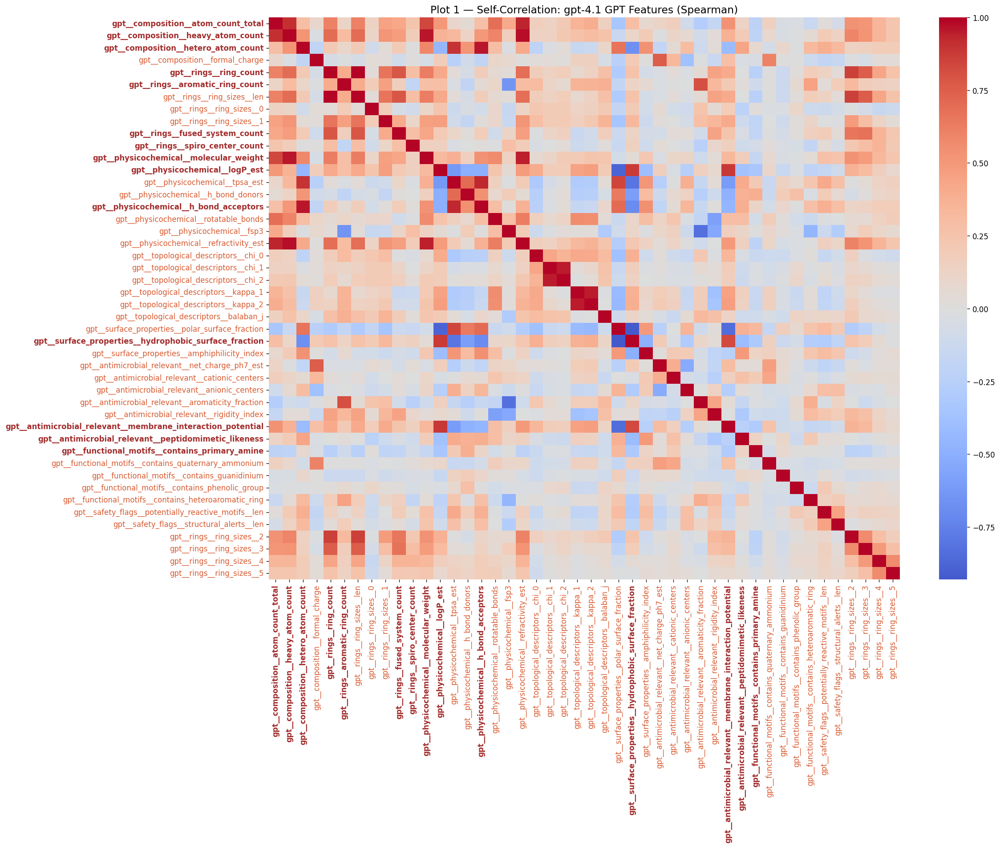

[Plot 2] Ordered Spearman cross-correlation


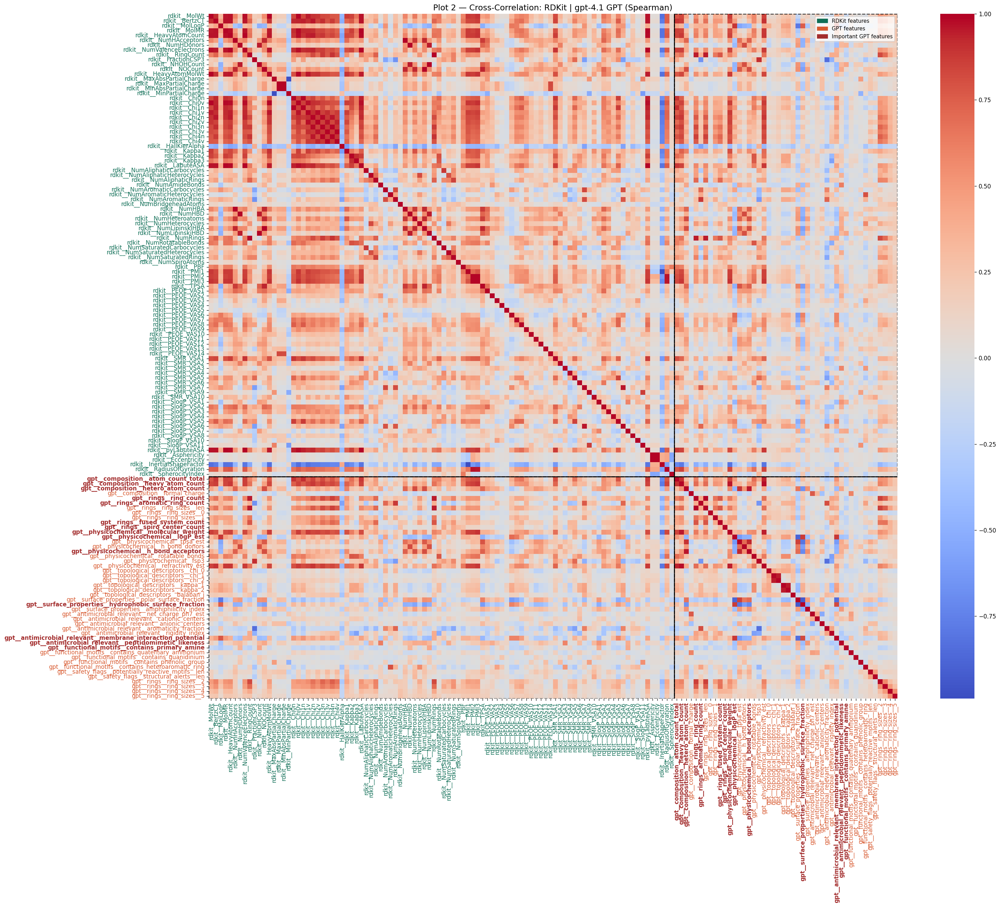

[Plot 3] Ordered Kendall cross-correlation


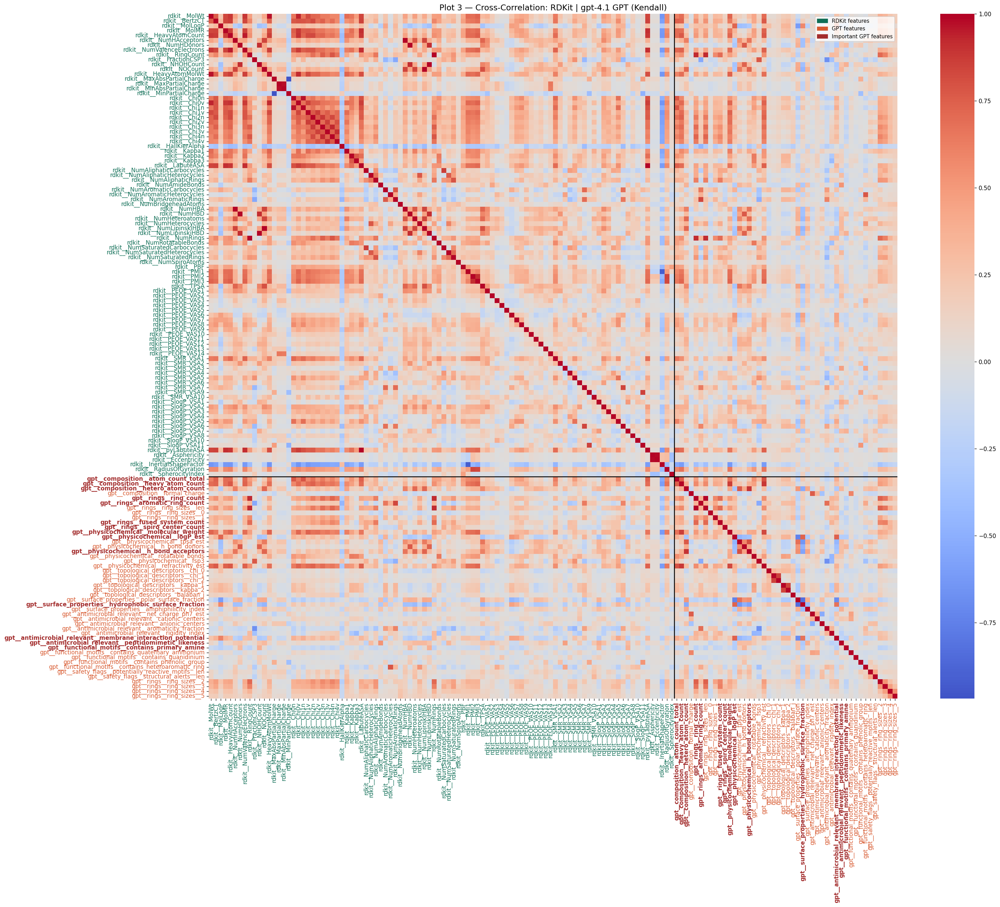

[Plot 4] Clustered heatmap


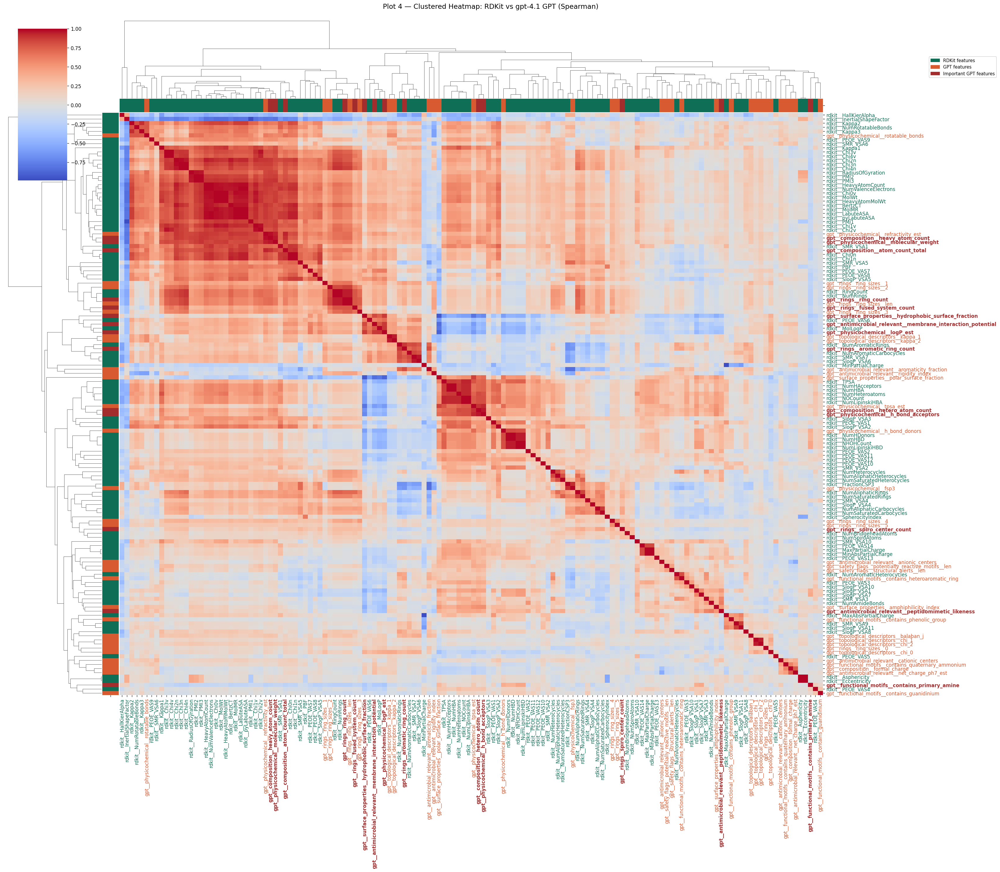

[Plot 5] MolWt scatter
  Spearman r = 0.8644  (p = 0.00e+00)


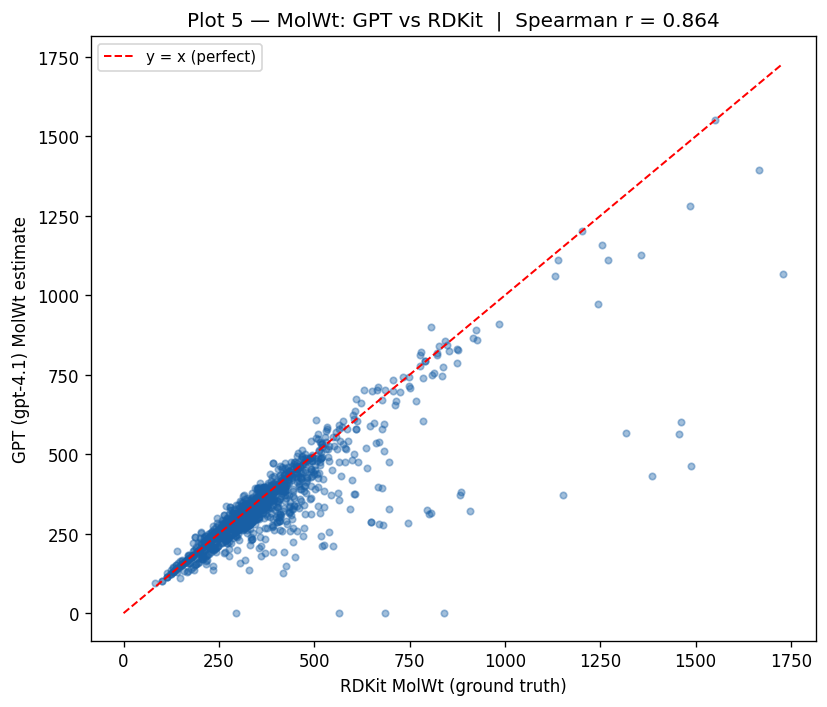

[Plot 6] Correlation network
  Nodes: 142  Edges: 819


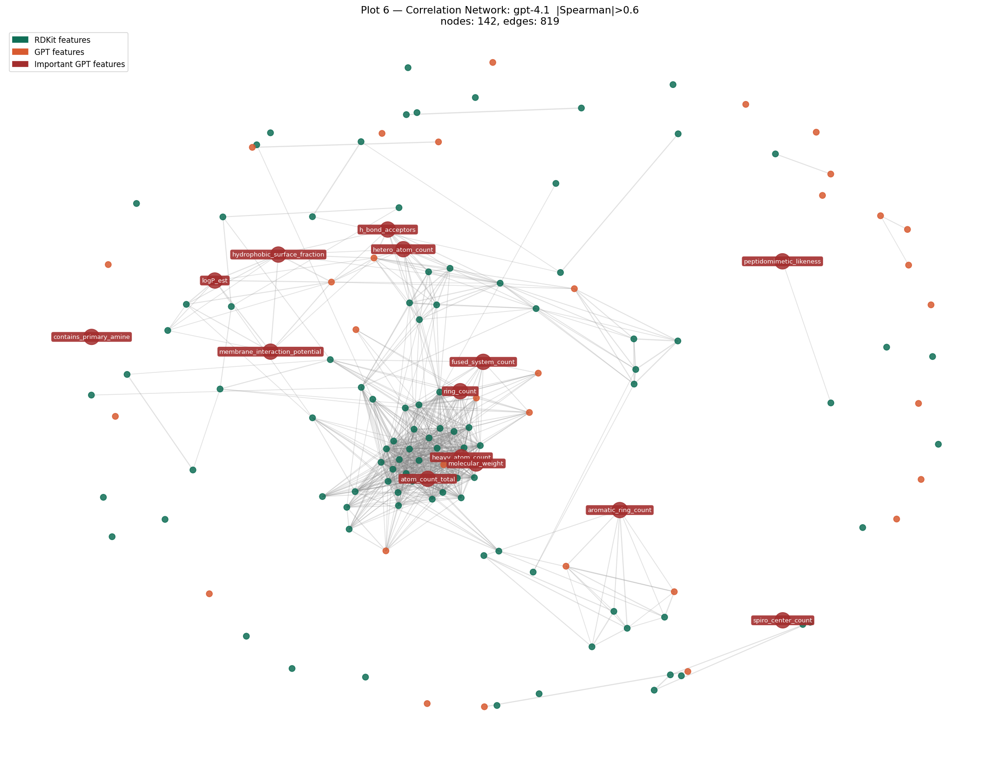

[Plot 7] Novelty bar chart


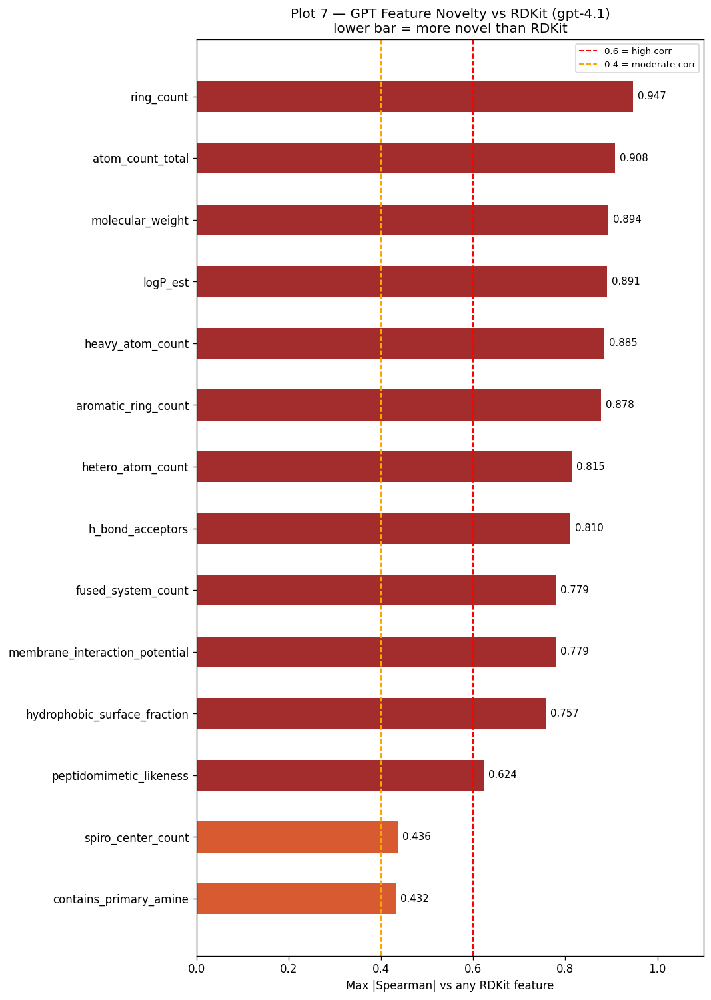


  KEY NOVELTY NUMBERS:
  contains_primary_amine                    max|r|=0.432  (rdkit__NHOHCount)
  spiro_center_count                        max|r|=0.436  (rdkit__NumSaturatedCarbocycles)
  peptidomimetic_likeness                   max|r|=0.624  (rdkit__NumAmideBonds)
  hydrophobic_surface_fraction              max|r|=0.757  (rdkit__MolLogP)
  membrane_interaction_potential            max|r|=0.779  (rdkit__MolLogP)
  fused_system_count                        max|r|=0.779  (rdkit__RingCount)
  h_bond_acceptors                          max|r|=0.810  (rdkit__NOCount)
  hetero_atom_count                         max|r|=0.815  (rdkit__NumHeteroatoms)
  aromatic_ring_count                       max|r|=0.878  (rdkit__NumAromaticRings)
  heavy_atom_count                          max|r|=0.885  (rdkit__PMI3)
  logP_est                                  max|r|=0.891  (rdkit__MolLogP)
  molecular_weight                          max|r|=0.894  (rdkit__PMI3)
  atom_count_total                      

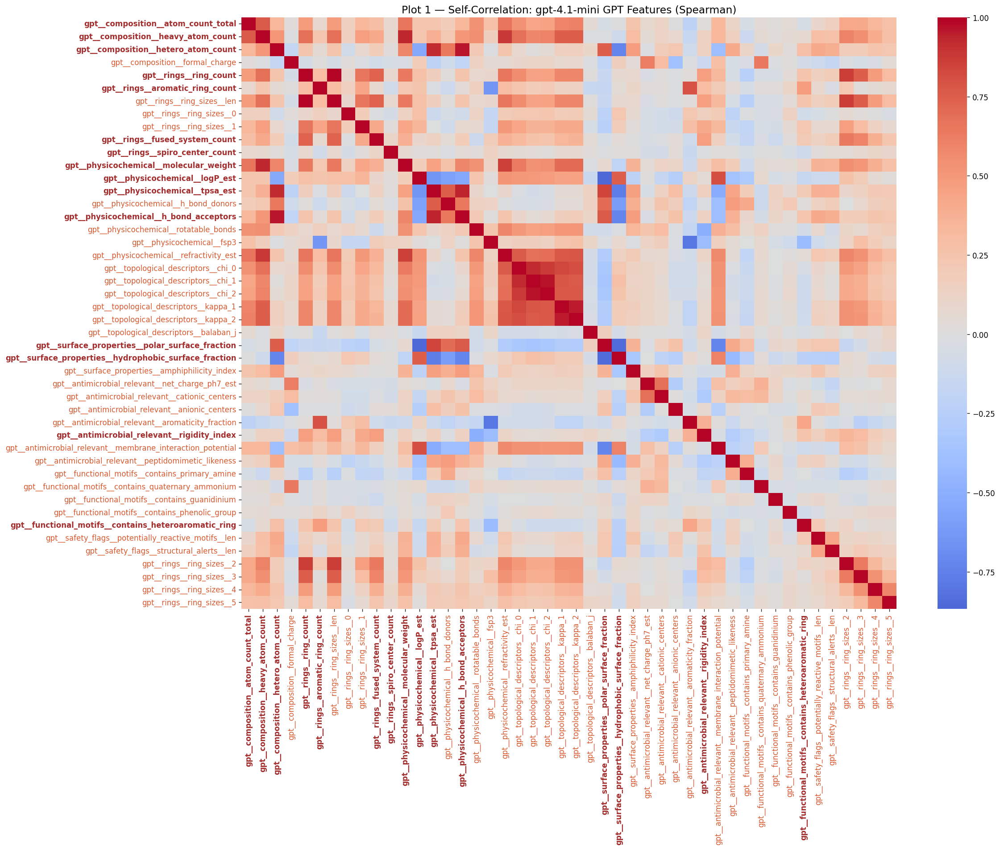

[Plot 2] Ordered Spearman cross-correlation


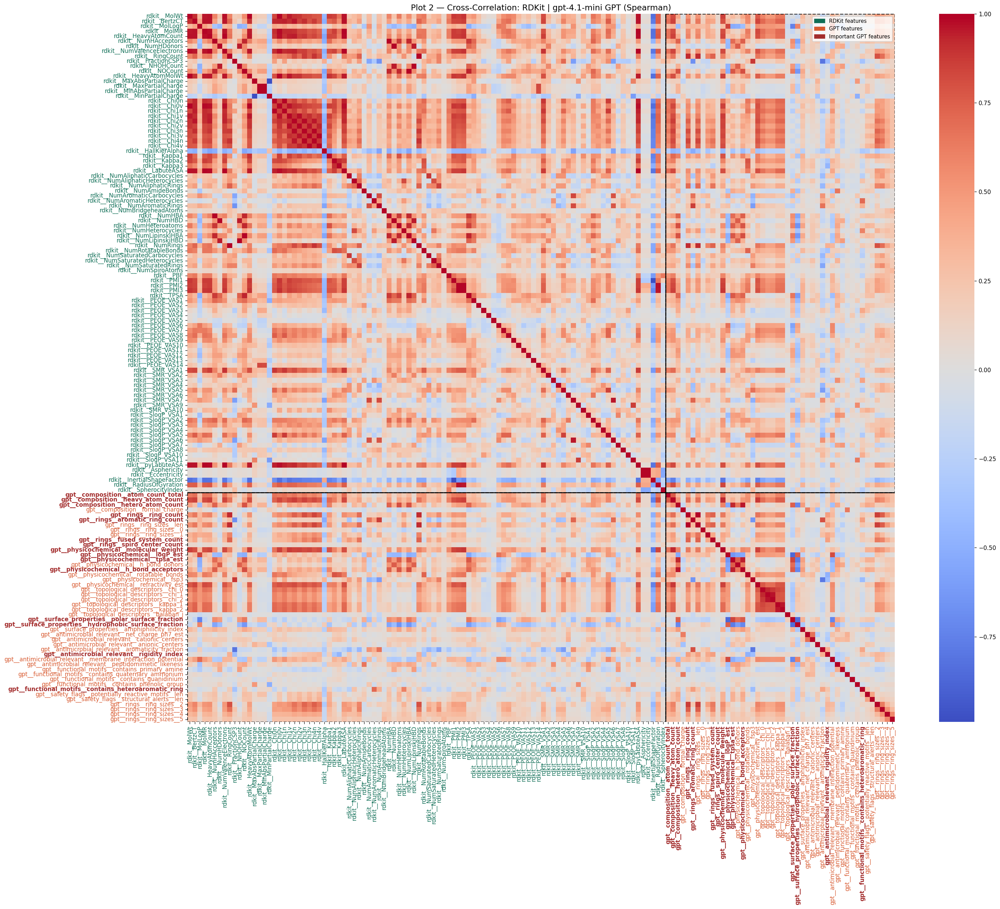

[Plot 3] Ordered Kendall cross-correlation


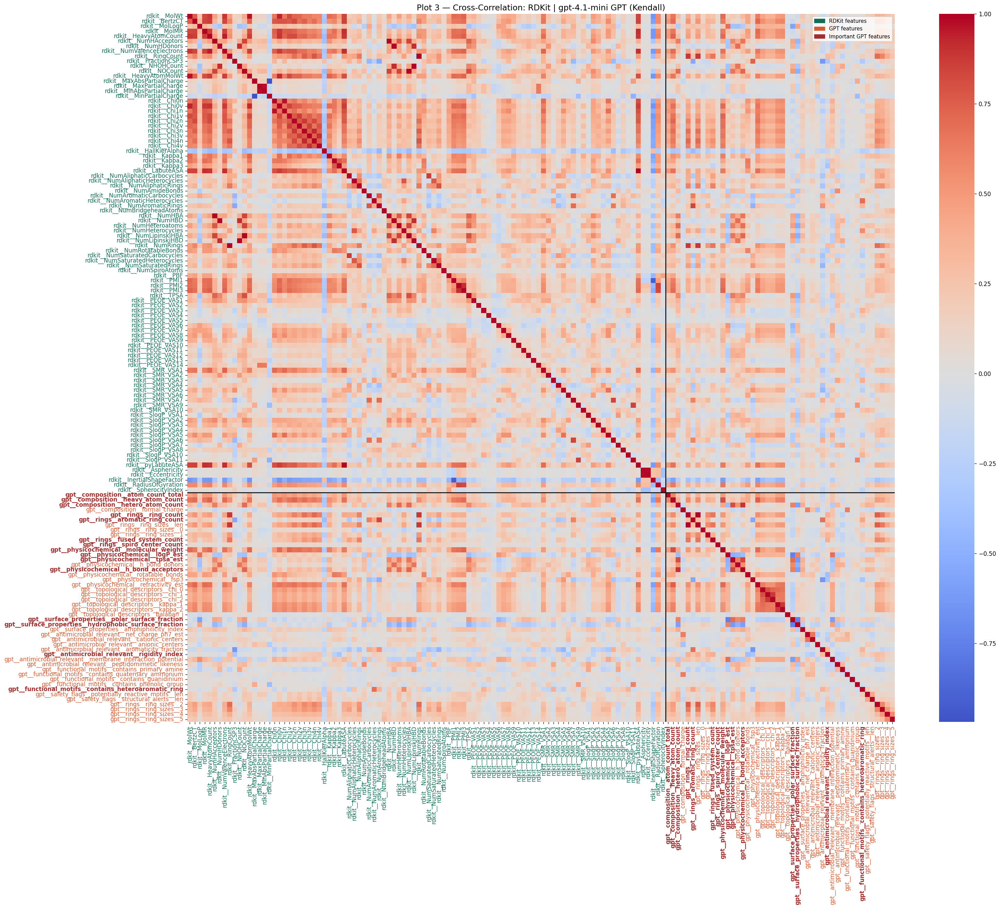

[Plot 4] Clustered heatmap


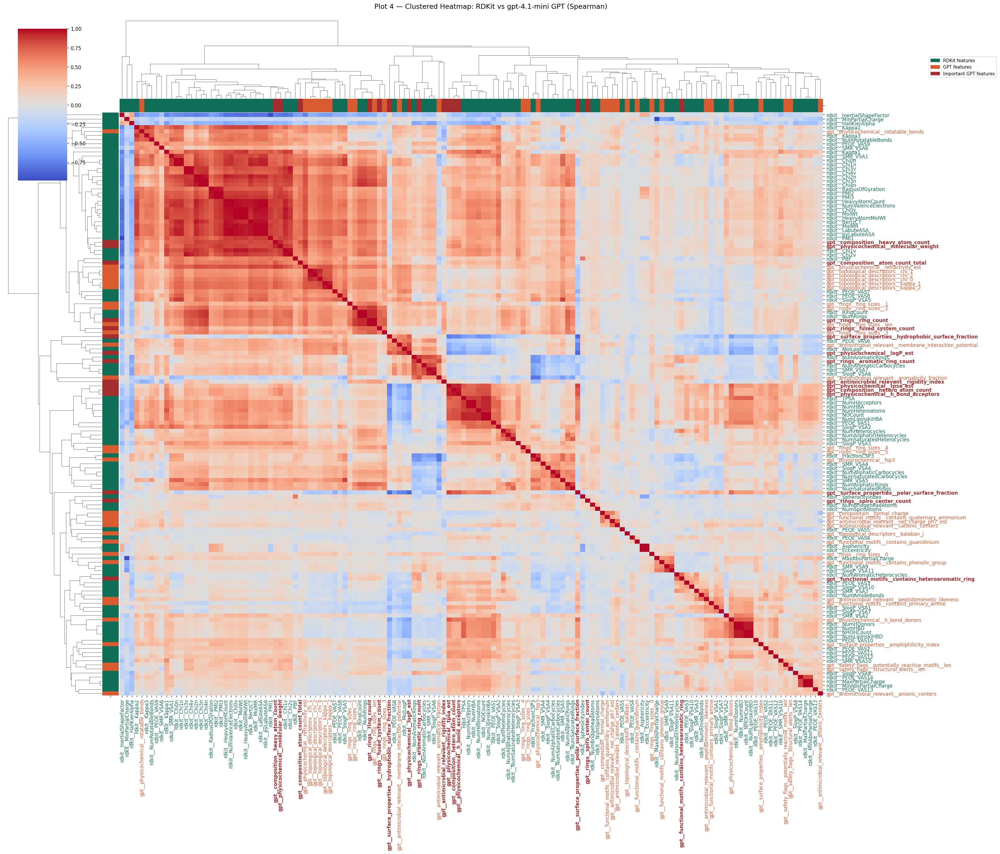

[Plot 5] MolWt scatter
  Spearman r = 0.8561  (p = 0.00e+00)


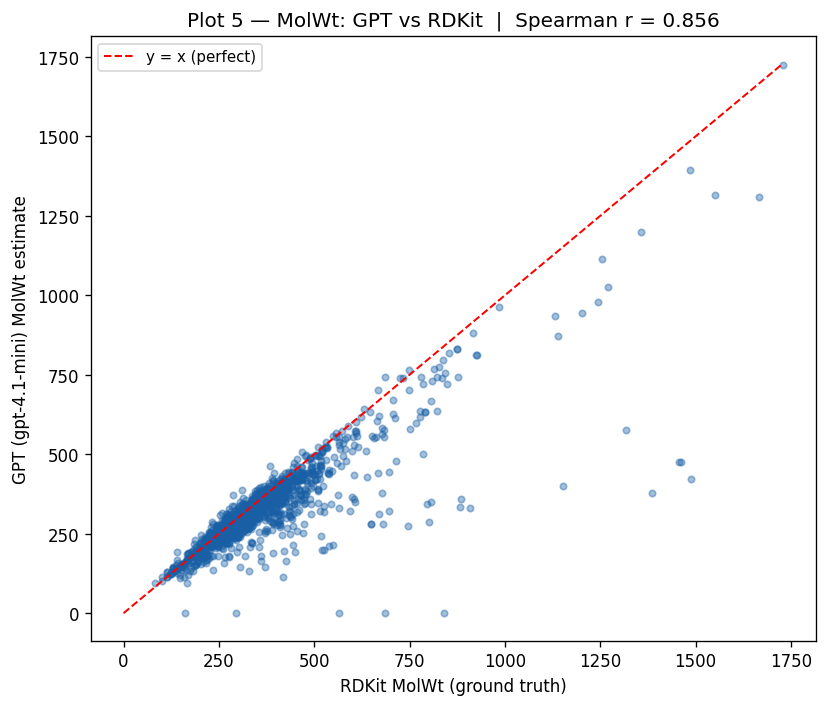

[Plot 6] Correlation network
  Nodes: 142  Edges: 890


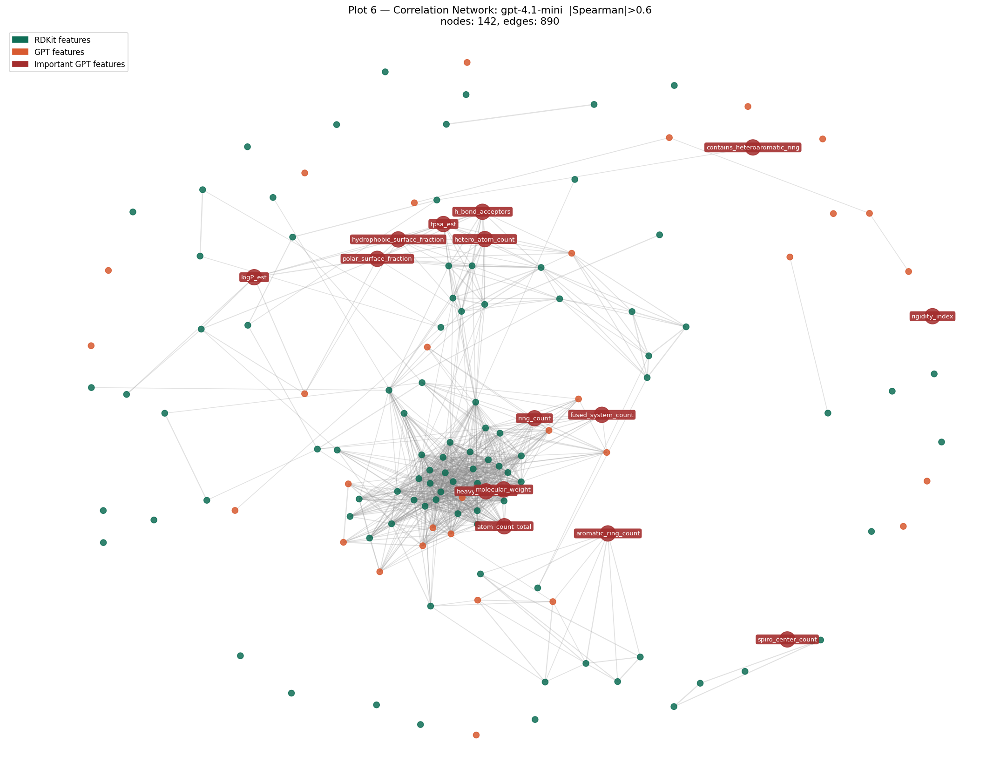

[Plot 7] Novelty bar chart


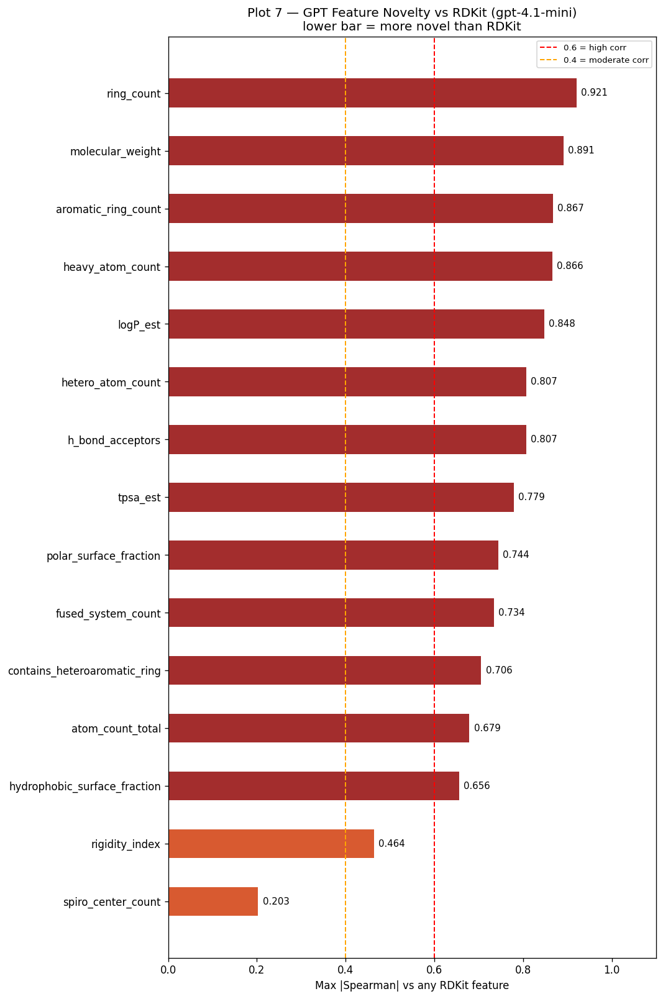


  KEY NOVELTY NUMBERS:
  spiro_center_count                        max|r|=0.203  (rdkit__NumSaturatedRings)
  rigidity_index                            max|r|=0.464  (rdkit__Kappa3)
  hydrophobic_surface_fraction              max|r|=0.656  (rdkit__NumHeteroatoms)
  atom_count_total                          max|r|=0.679  (rdkit__BertzCT)
  contains_heteroaromatic_ring              max|r|=0.706  (rdkit__NumAromaticHeterocycles)
  fused_system_count                        max|r|=0.734  (rdkit__RingCount)
  polar_surface_fraction                    max|r|=0.744  (rdkit__MolLogP)
  tpsa_est                                  max|r|=0.779  (rdkit__NOCount)
  h_bond_acceptors                          max|r|=0.807  (rdkit__NOCount)
  hetero_atom_count                         max|r|=0.807  (rdkit__NumHeteroatoms)
  logP_est                                  max|r|=0.848  (rdkit__MolLogP)
  heavy_atom_count                          max|r|=0.866  (rdkit__Chi2n)
  aromatic_ring_count                

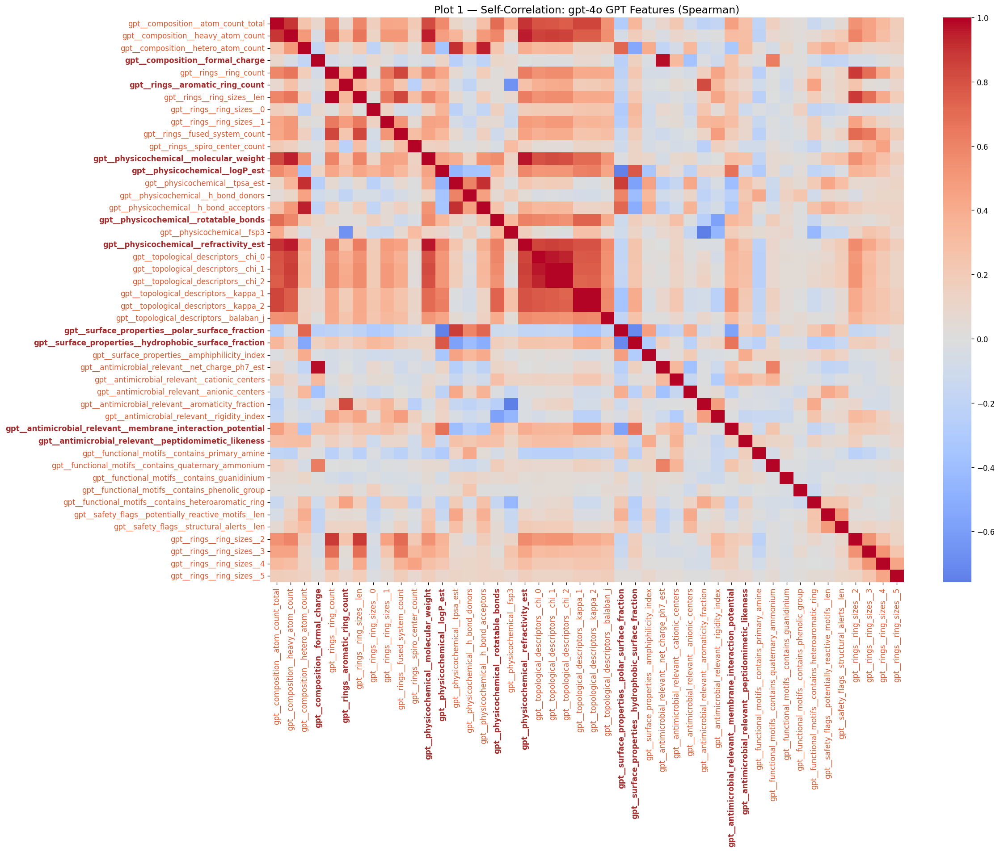

[Plot 2] Ordered Spearman cross-correlation


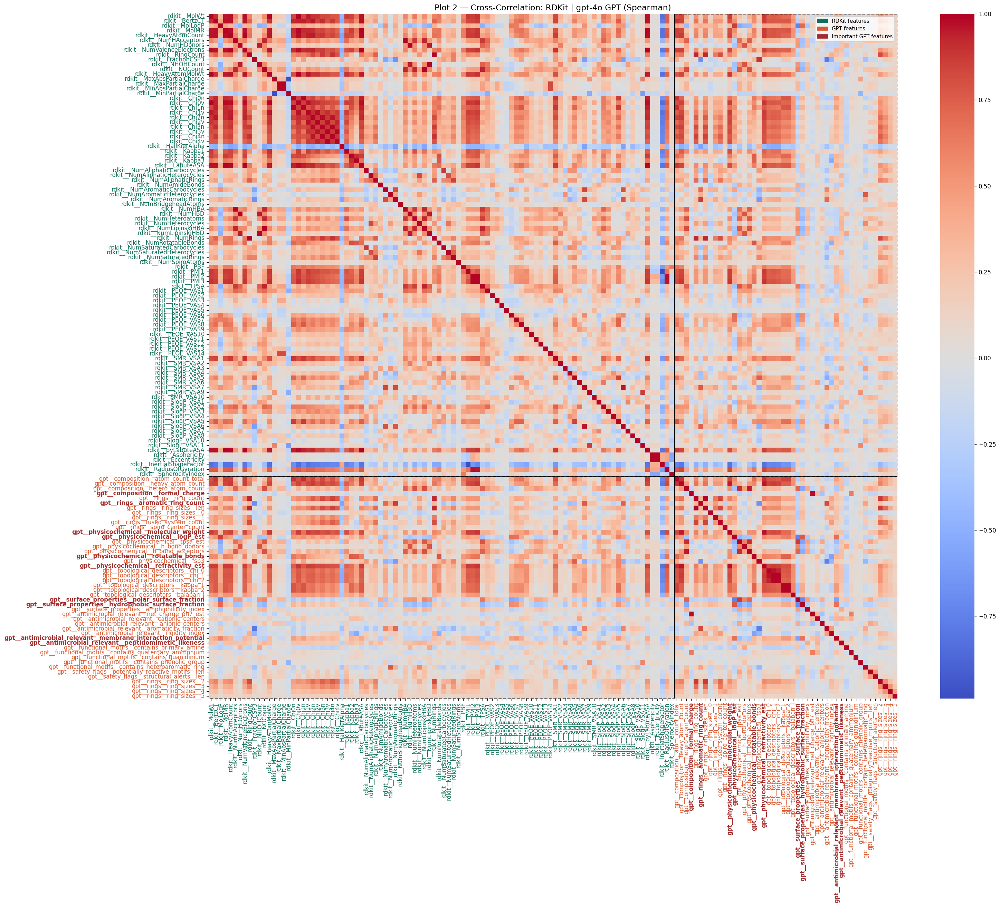

[Plot 3] Ordered Kendall cross-correlation


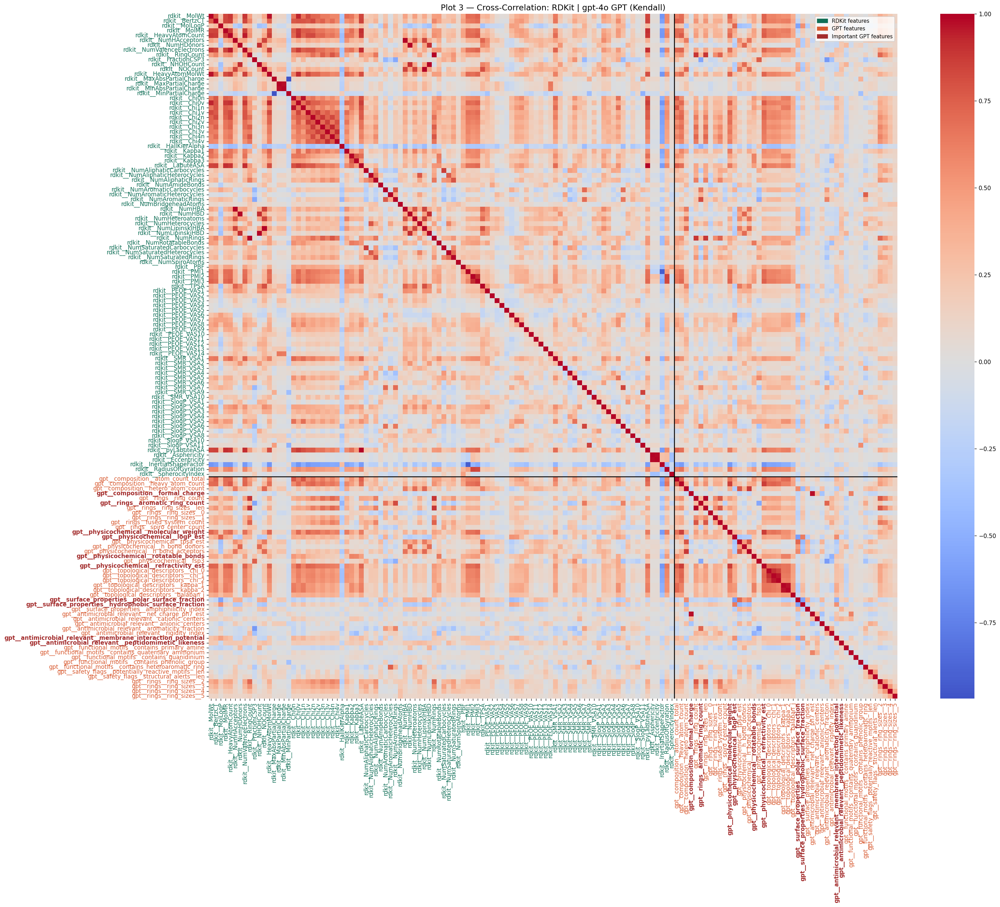

[Plot 4] Clustered heatmap


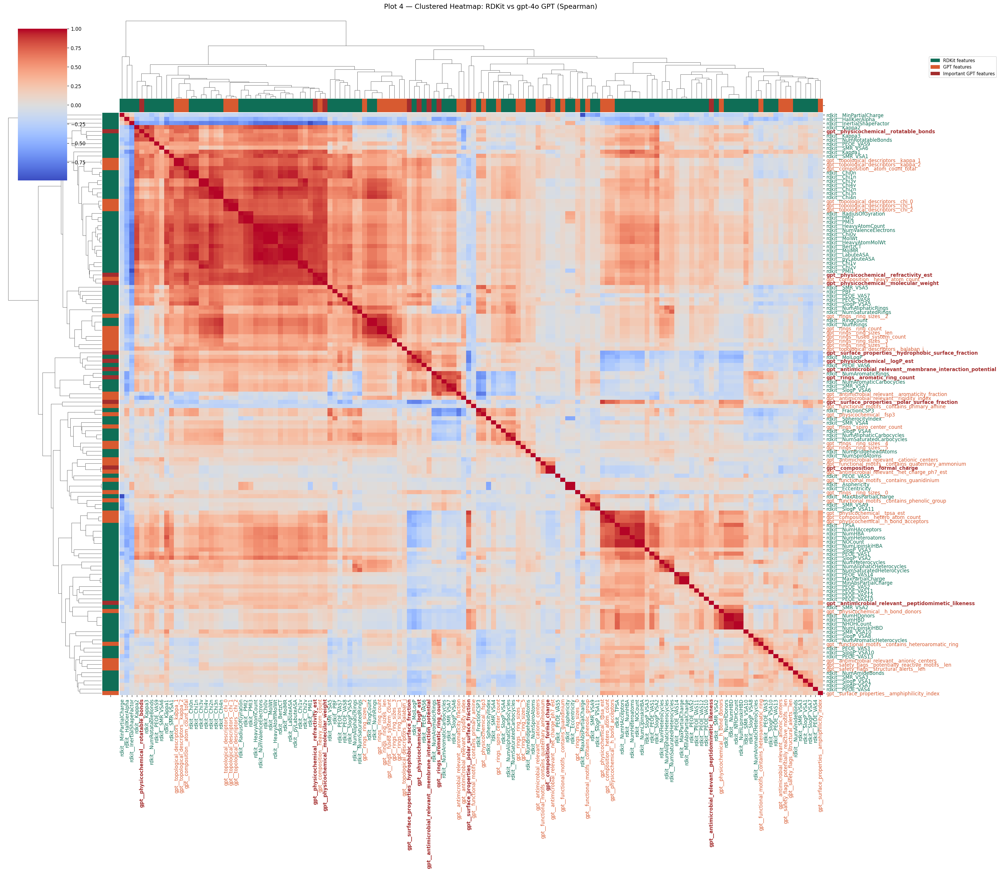

[Plot 5] MolWt scatter
  Spearman r = 0.8626  (p = 0.00e+00)


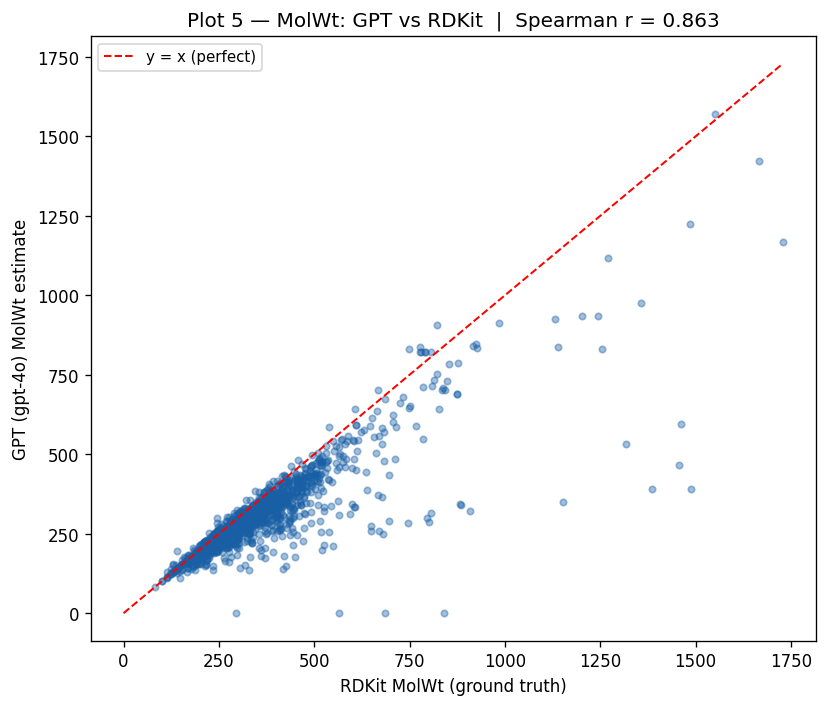

[Plot 6] Correlation network
  Nodes: 142  Edges: 949


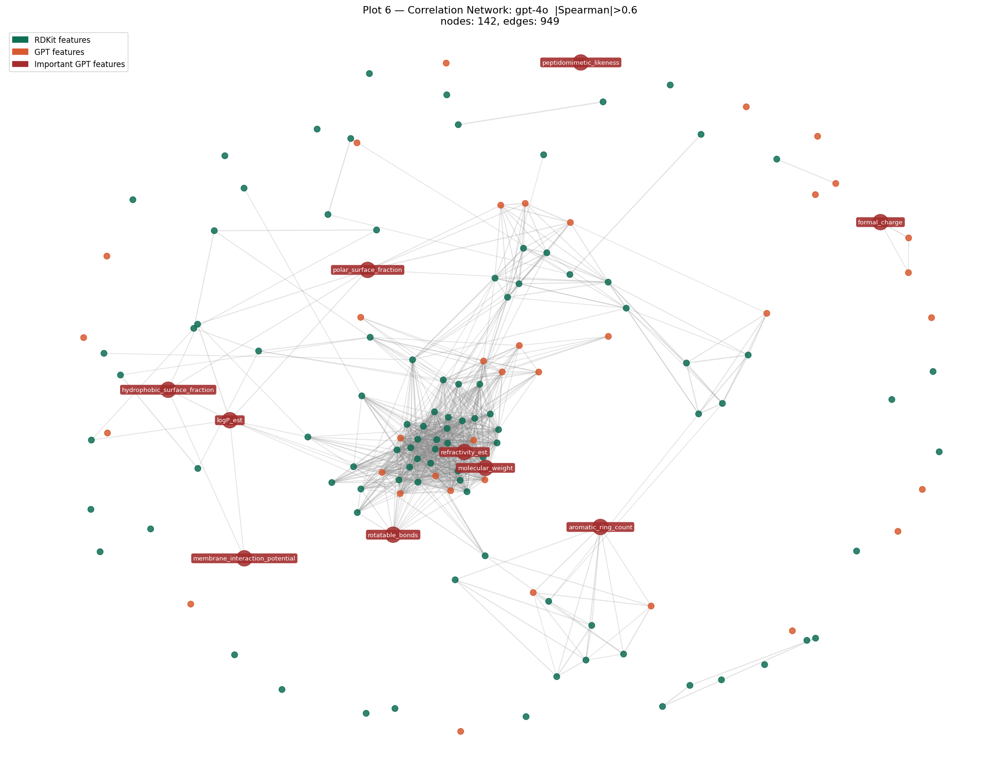

[Plot 7] Novelty bar chart


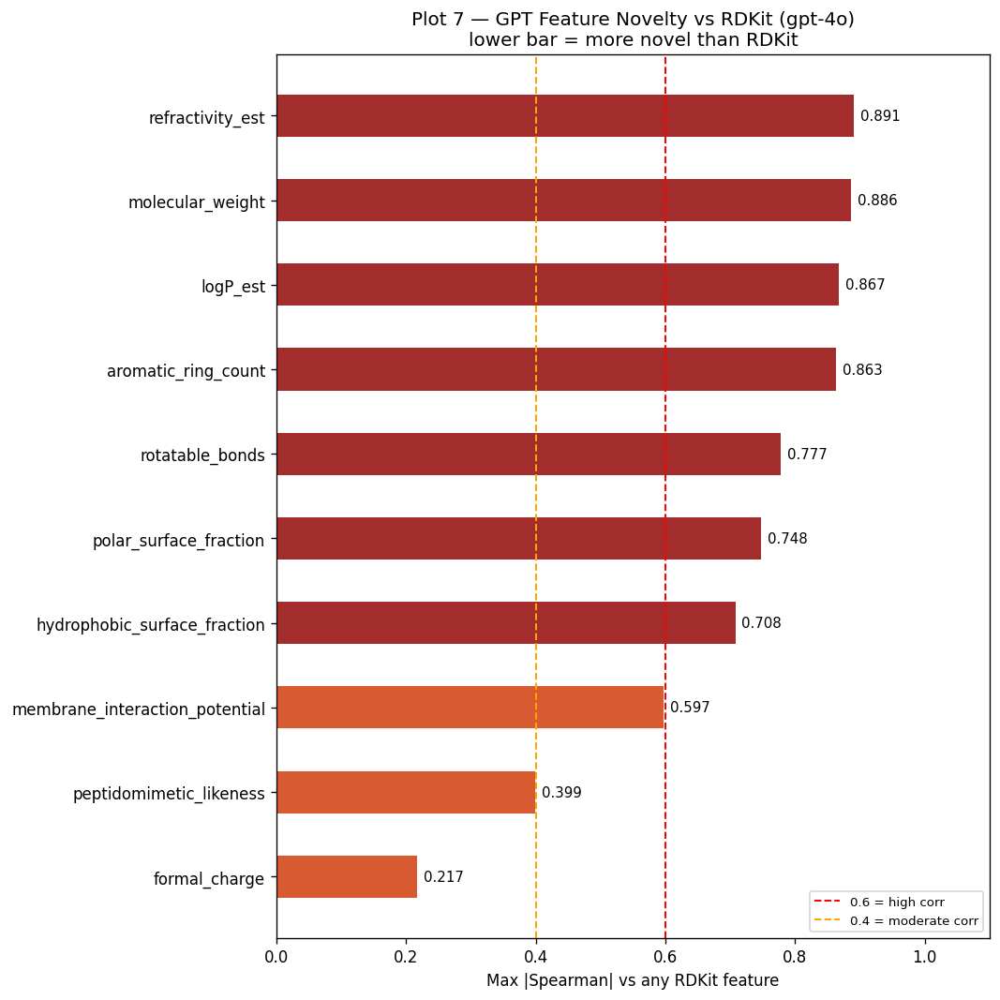


  KEY NOVELTY NUMBERS:
  formal_charge                             max|r|=0.217  (rdkit__TPSA)
  peptidomimetic_likeness                   max|r|=0.399  (rdkit__SMR_VSA3)
  membrane_interaction_potential            max|r|=0.597  (rdkit__MolLogP)
  hydrophobic_surface_fraction              max|r|=0.708  (rdkit__MolLogP)
  polar_surface_fraction                    max|r|=0.748  (rdkit__MolLogP)
  rotatable_bonds                           max|r|=0.777  (rdkit__NumRotatableBonds)
  aromatic_ring_count                       max|r|=0.863  (rdkit__NumAromaticRings)
  logP_est                                  max|r|=0.867  (rdkit__MolLogP)
  molecular_weight                          max|r|=0.886  (rdkit__PMI3)
  refractivity_est                          max|r|=0.891  (rdkit__PMI3)

  Plots saved to: D:\Hiwi\GPT+Mole\GPT+Mole\data\plots_final\gpt-4o

  MODEL: gpt-4o-mini
Loading data...
  RDKit: (1197, 96)  GPT: (1197, 45)  Important: 10
  Important features: ['hetero_atom_count', 'fused_syste

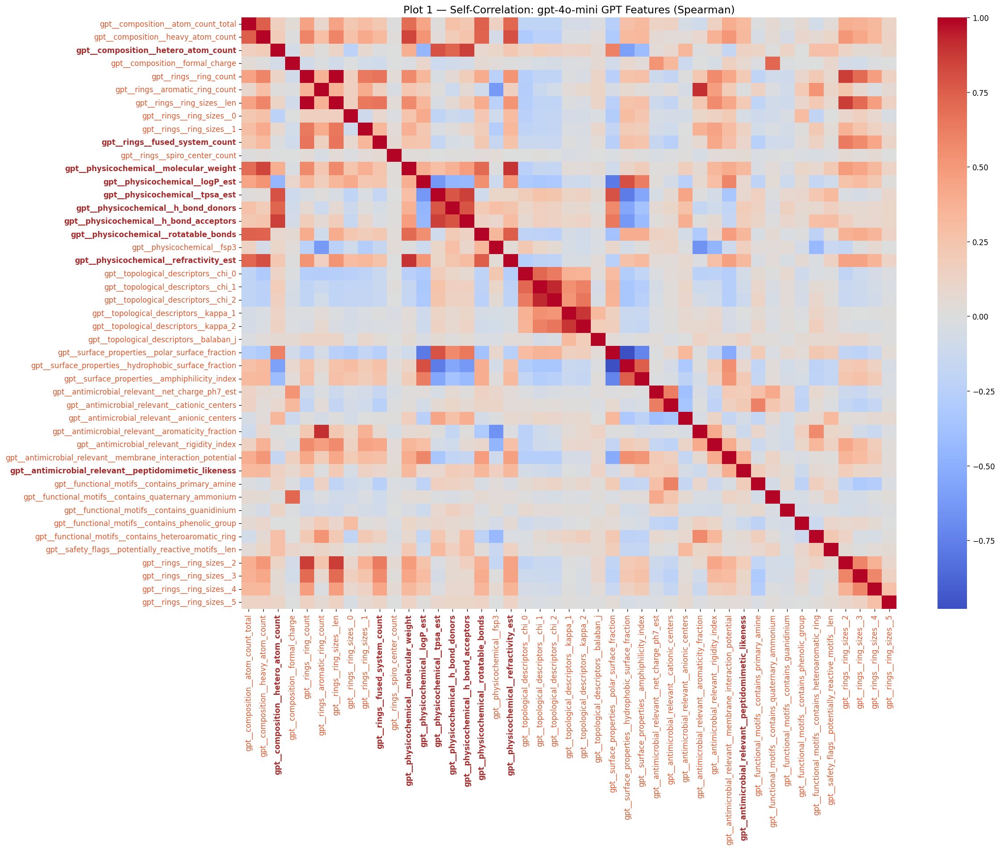

[Plot 2] Ordered Spearman cross-correlation


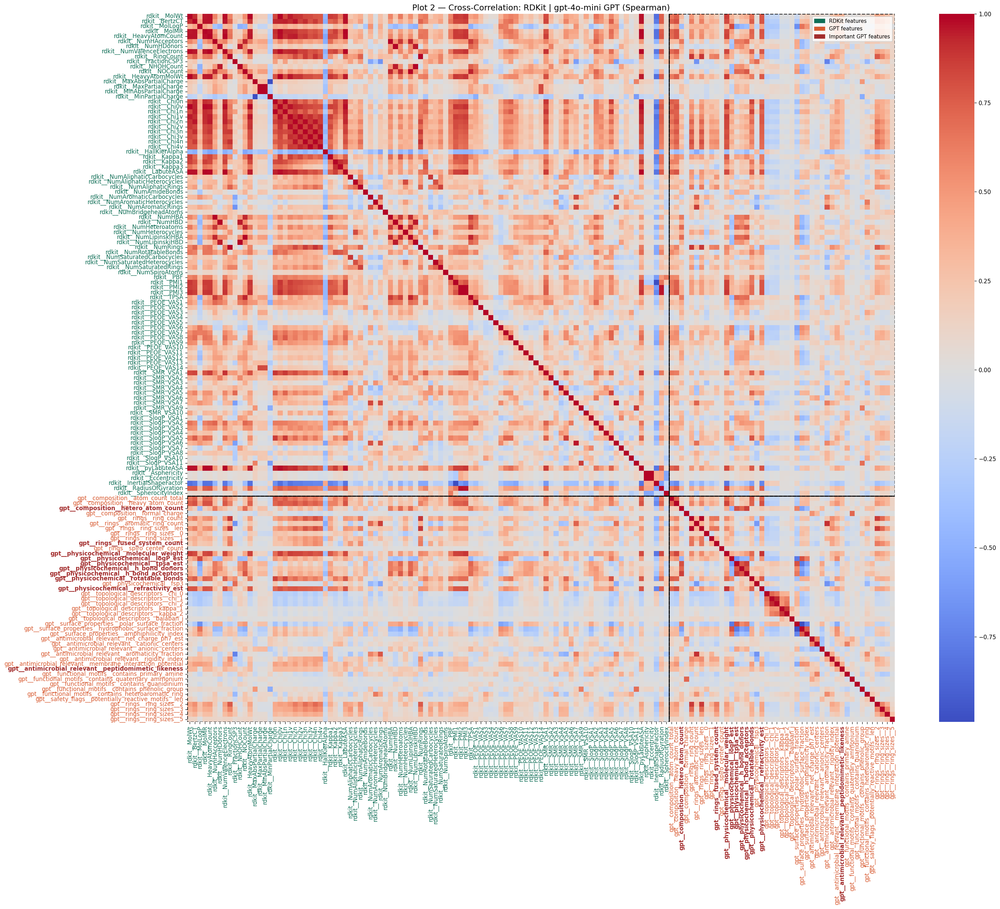

[Plot 3] Ordered Kendall cross-correlation


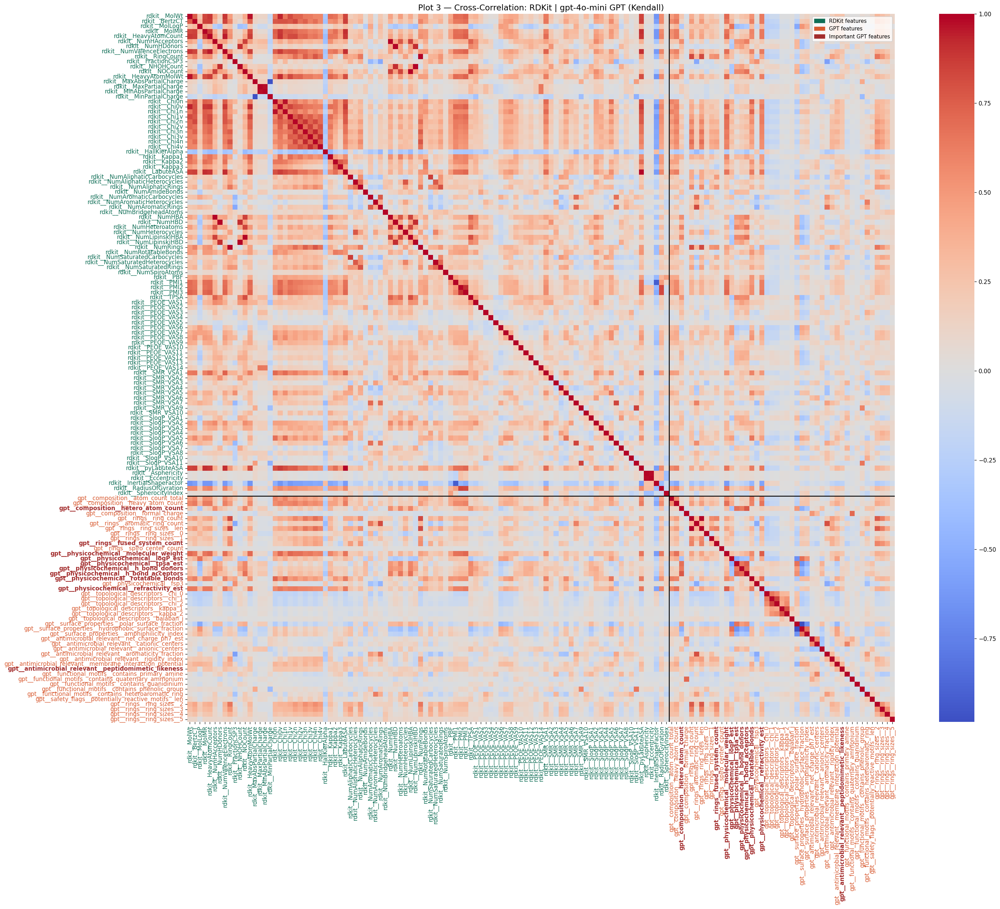

[Plot 4] Clustered heatmap


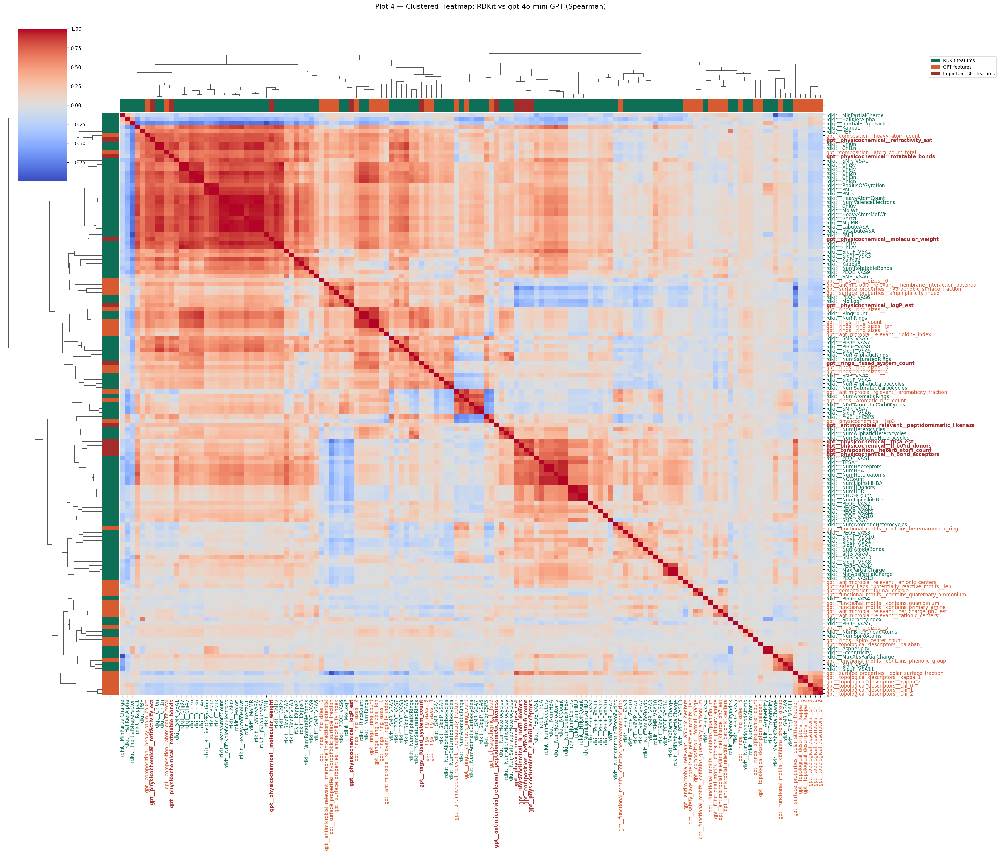

[Plot 5] MolWt scatter
  Spearman r = 0.8610  (p = 0.00e+00)


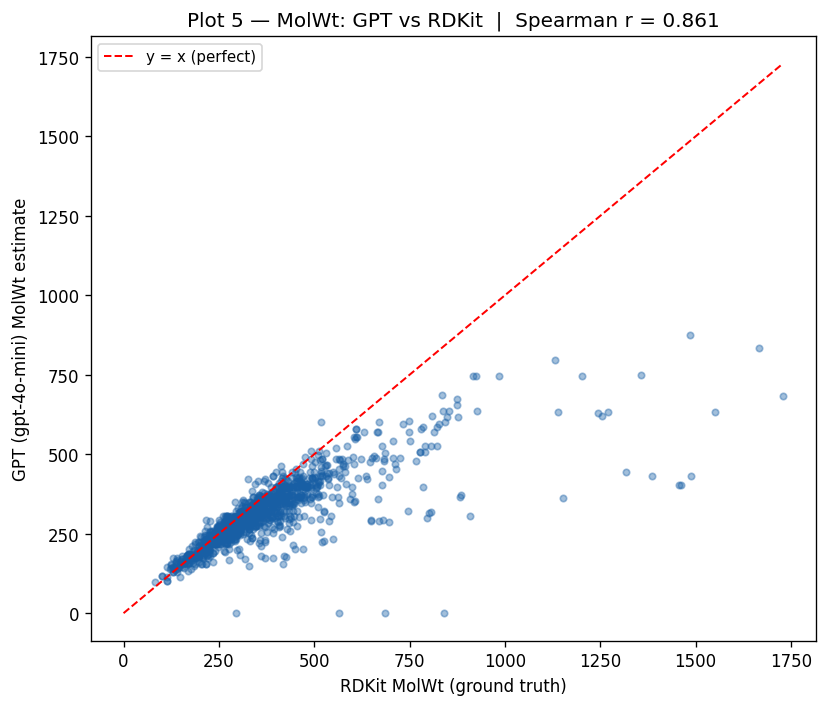

[Plot 6] Correlation network
  Nodes: 141  Edges: 797


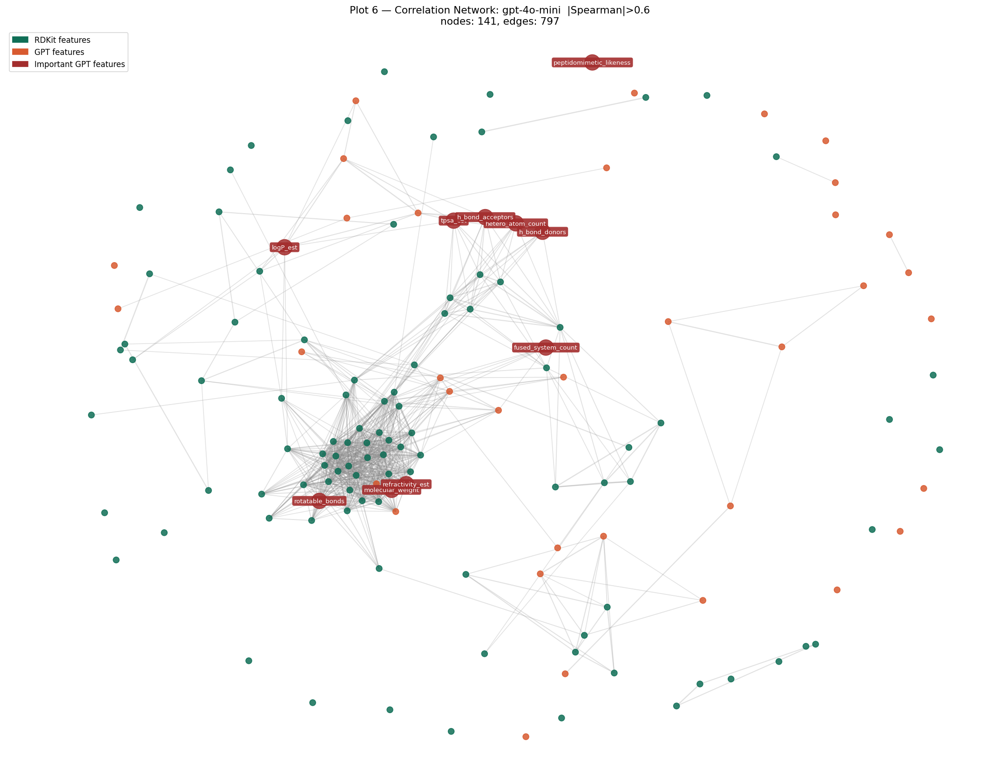

[Plot 7] Novelty bar chart


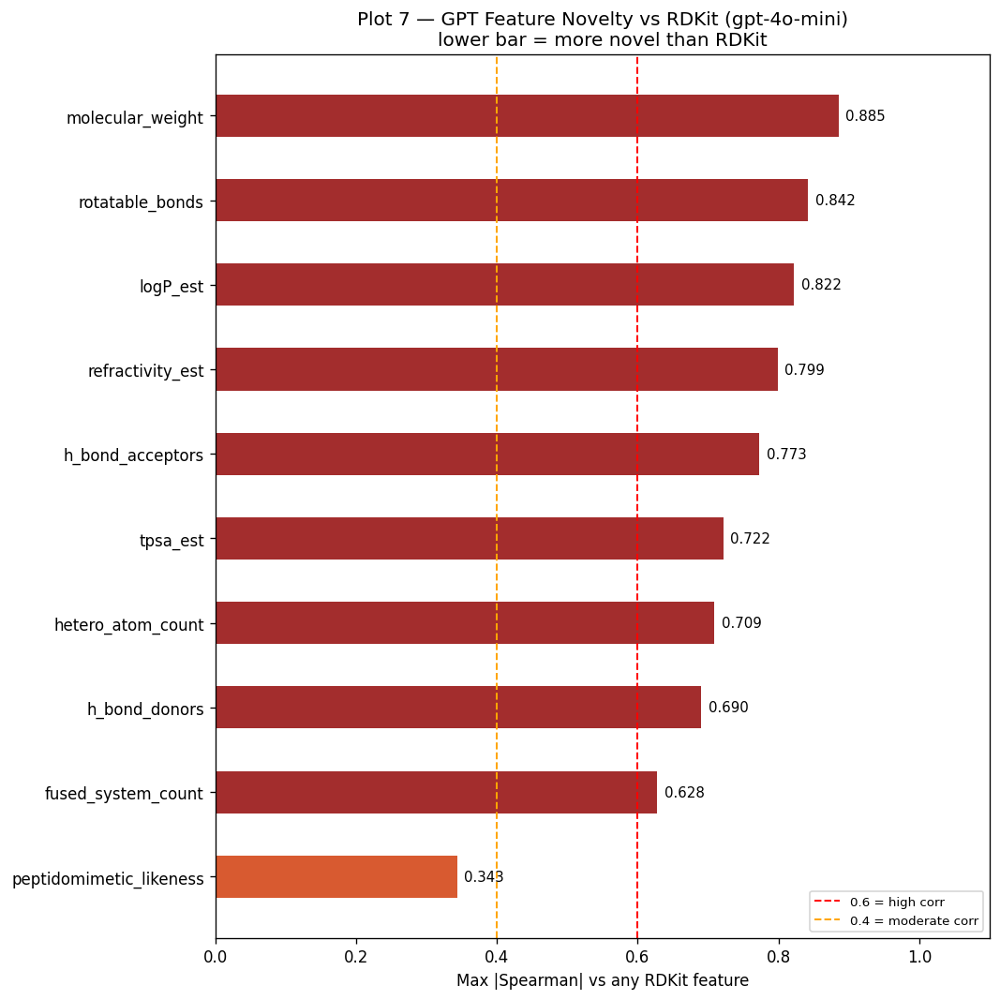


  KEY NOVELTY NUMBERS:
  peptidomimetic_likeness                   max|r|=0.343  (rdkit__LabuteASA)
  fused_system_count                        max|r|=0.628  (rdkit__RingCount)
  h_bond_donors                             max|r|=0.690  (rdkit__NOCount)
  hetero_atom_count                         max|r|=0.709  (rdkit__NumHeteroatoms)
  tpsa_est                                  max|r|=0.722  (rdkit__TPSA)
  h_bond_acceptors                          max|r|=0.773  (rdkit__NOCount)
  refractivity_est                          max|r|=0.799  (rdkit__PMI3)
  logP_est                                  max|r|=0.822  (rdkit__MolLogP)
  rotatable_bonds                           max|r|=0.842  (rdkit__Chi1n)
  molecular_weight                          max|r|=0.885  (rdkit__PMI3)

  Plots saved to: D:\Hiwi\GPT+Mole\GPT+Mole\data\plots_final\gpt-4o-mini

  MODEL: gpt-5.1
Loading data...
  RDKit: (1197, 96)  GPT: (1197, 46)  Important: 14
  Important features: ['atom_count_total', 'heavy_atom_count', 'he

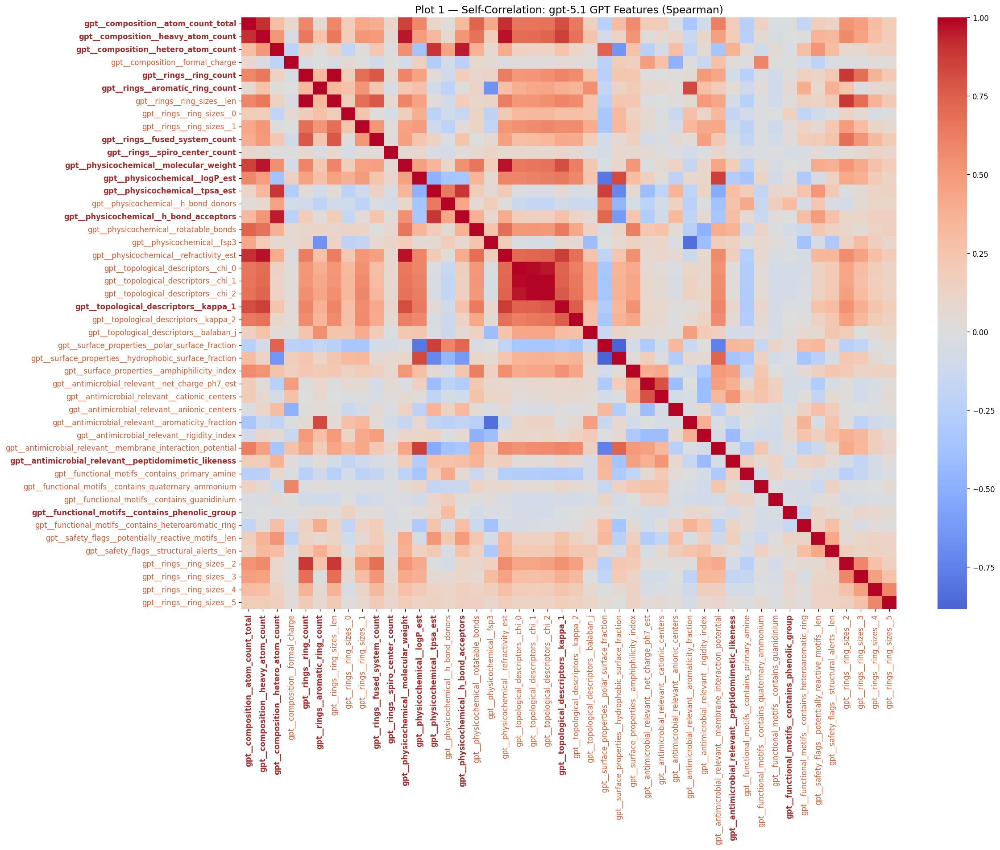

[Plot 2] Ordered Spearman cross-correlation


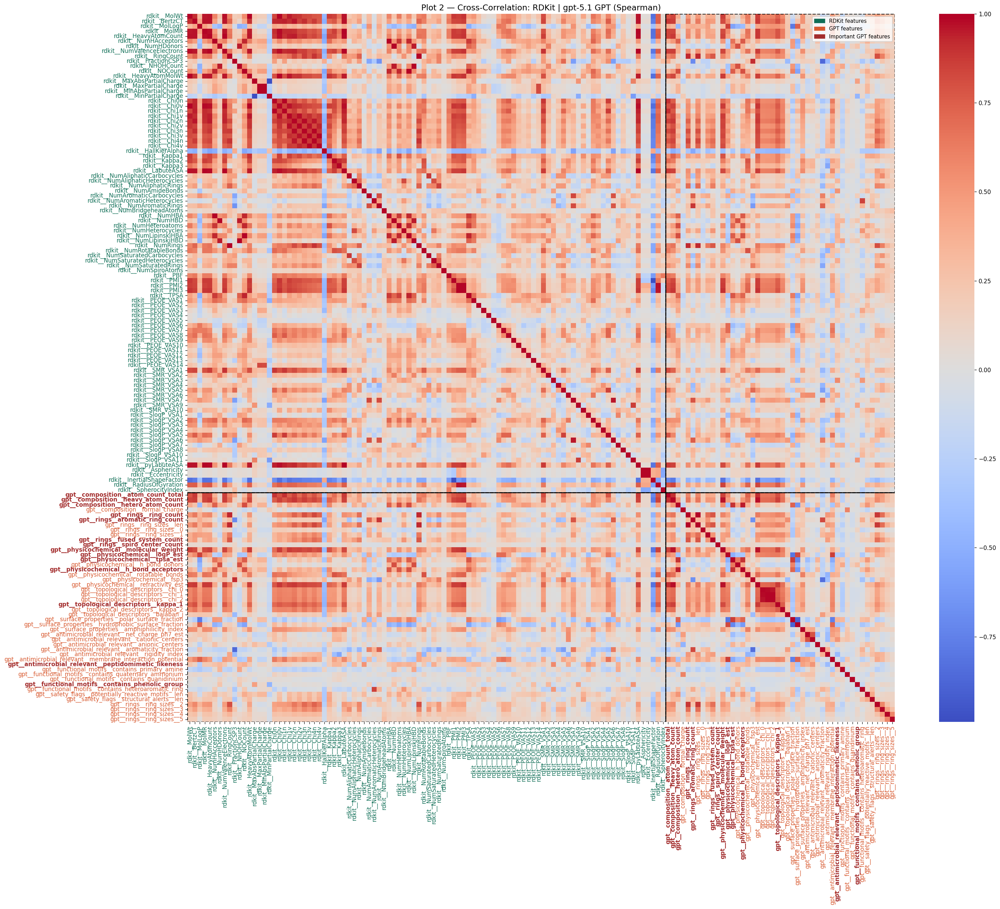

[Plot 3] Ordered Kendall cross-correlation


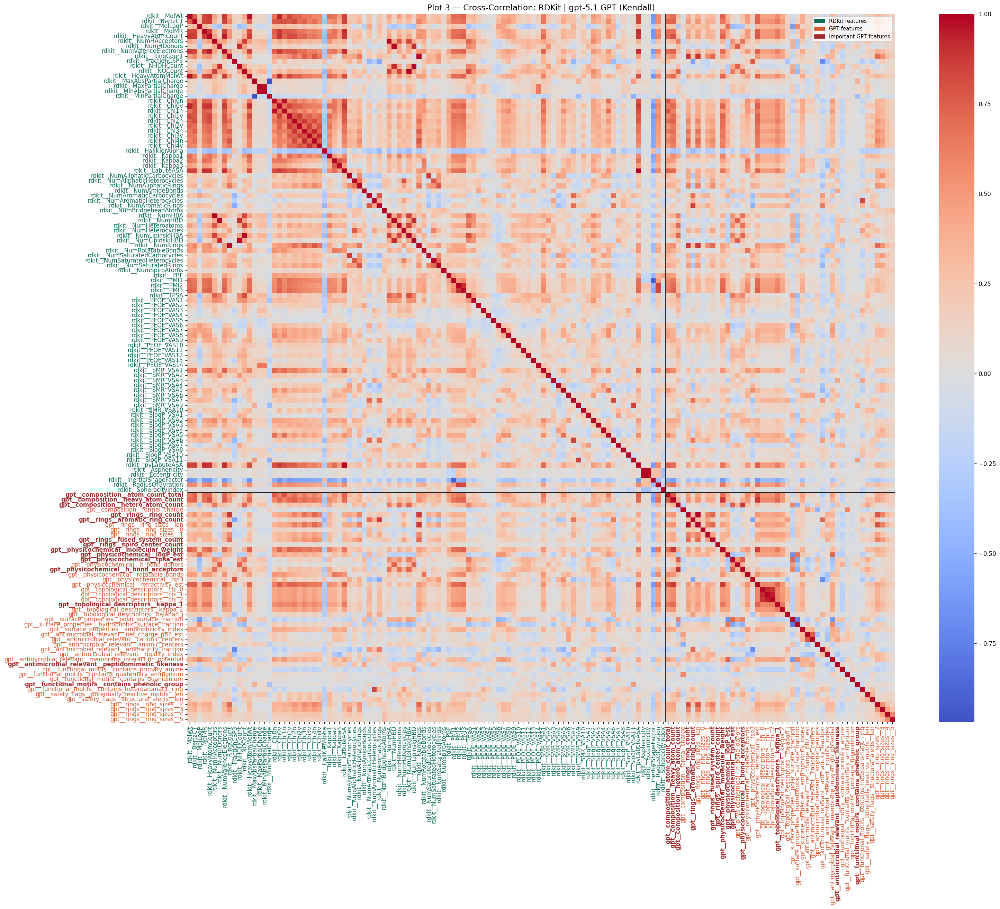

[Plot 4] Clustered heatmap


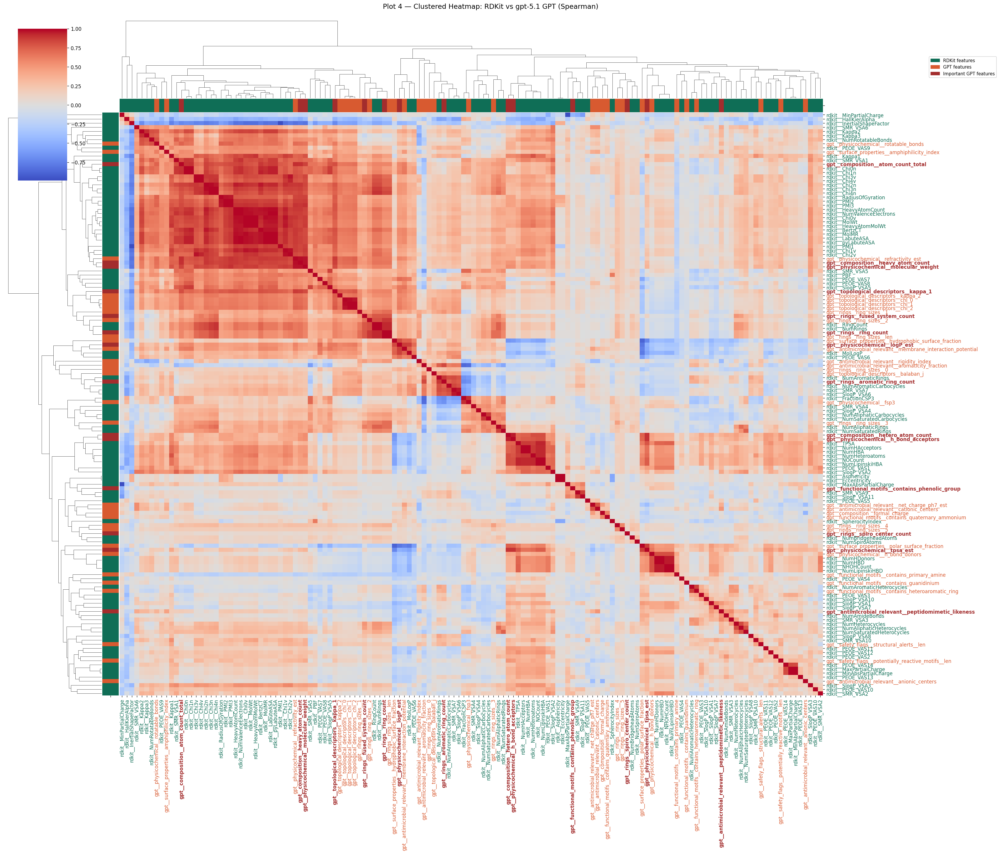

[Plot 5] MolWt scatter
  Spearman r = 0.8670  (p = 0.00e+00)


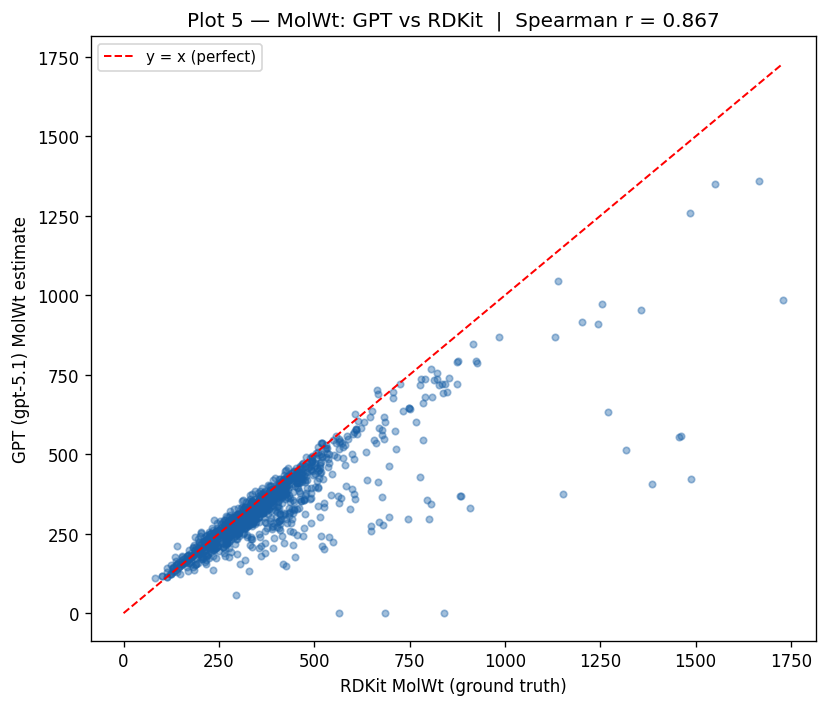

[Plot 6] Correlation network
  Nodes: 142  Edges: 926


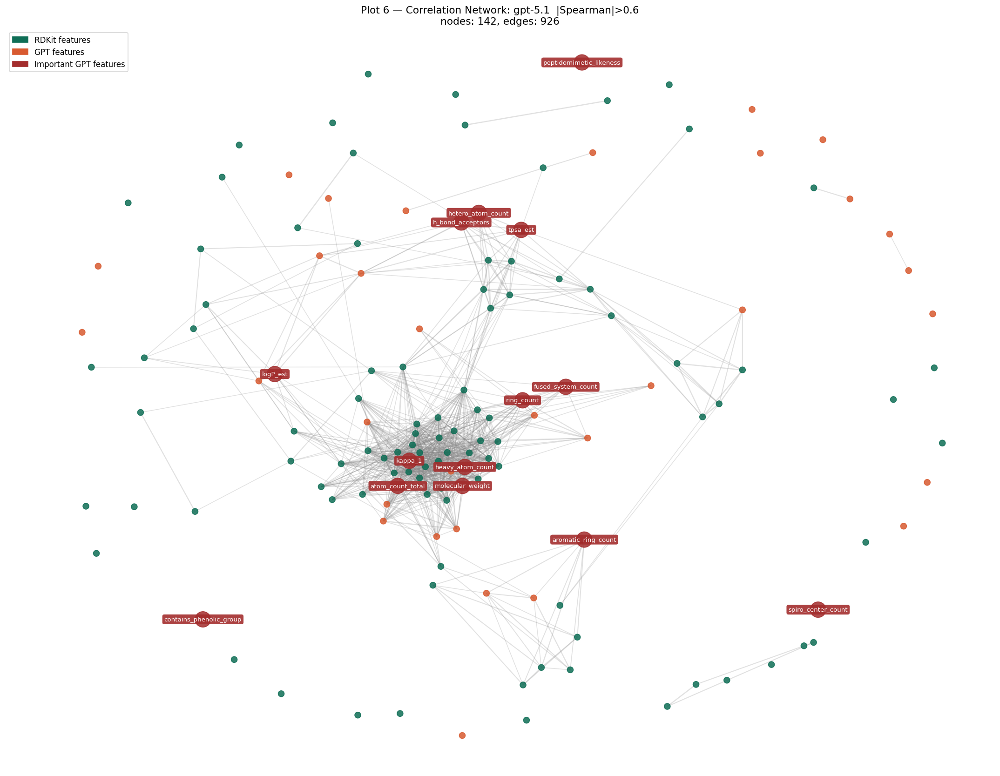

[Plot 7] Novelty bar chart


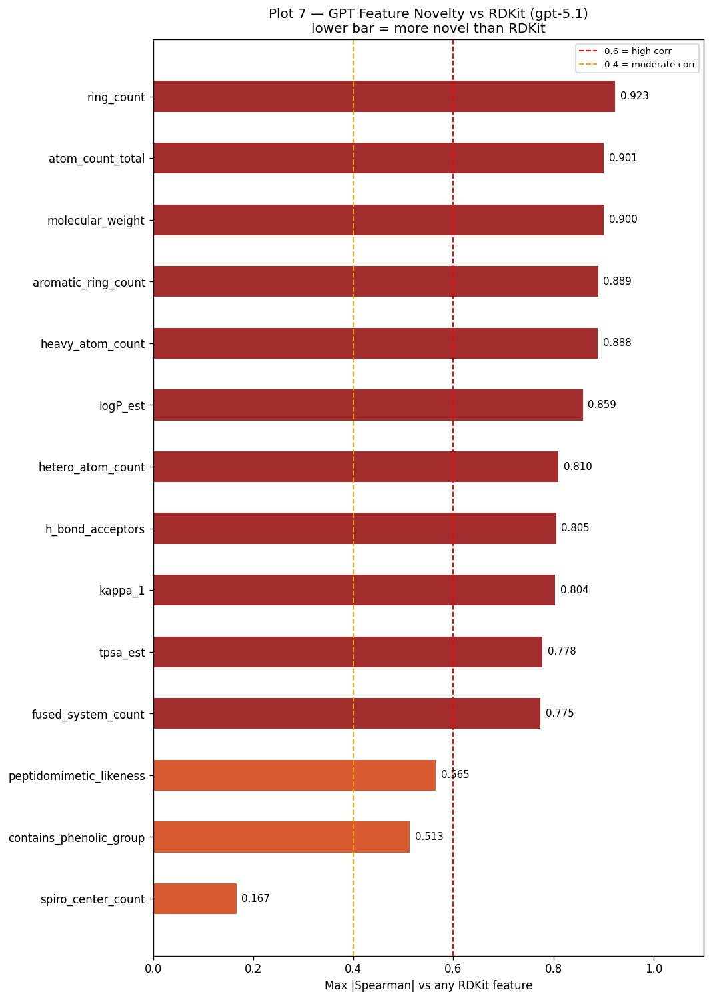


  KEY NOVELTY NUMBERS:
  spiro_center_count                        max|r|=0.167  (rdkit__NumSaturatedCarbocycles)
  contains_phenolic_group                   max|r|=0.513  (rdkit__SlogP_VSA11)
  peptidomimetic_likeness                   max|r|=0.565  (rdkit__SMR_VSA3)
  fused_system_count                        max|r|=0.775  (rdkit__RingCount)
  tpsa_est                                  max|r|=0.778  (rdkit__TPSA)
  kappa_1                                   max|r|=0.804  (rdkit__BertzCT)
  h_bond_acceptors                          max|r|=0.805  (rdkit__NOCount)
  hetero_atom_count                         max|r|=0.810  (rdkit__NumHeteroatoms)
  logP_est                                  max|r|=0.859  (rdkit__MolLogP)
  heavy_atom_count                          max|r|=0.888  (rdkit__PMI3)
  aromatic_ring_count                       max|r|=0.889  (rdkit__NumAromaticRings)
  molecular_weight                          max|r|=0.900  (rdkit__PMI3)
  atom_count_total                          ma

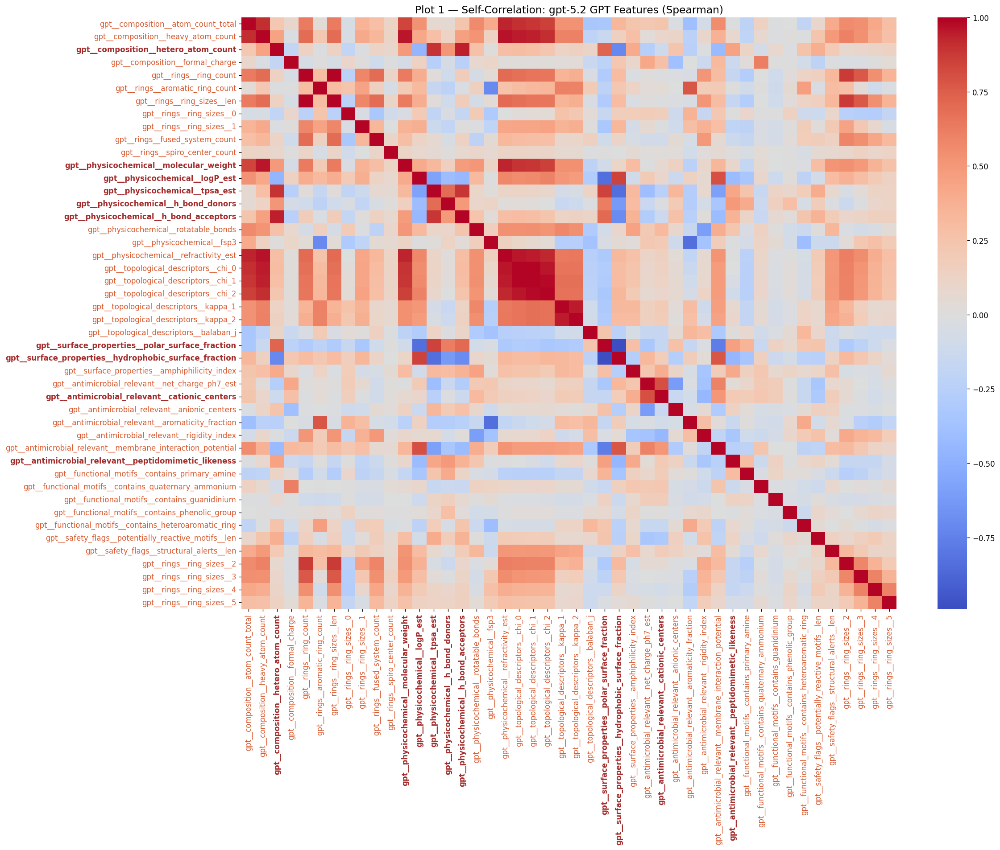

[Plot 2] Ordered Spearman cross-correlation


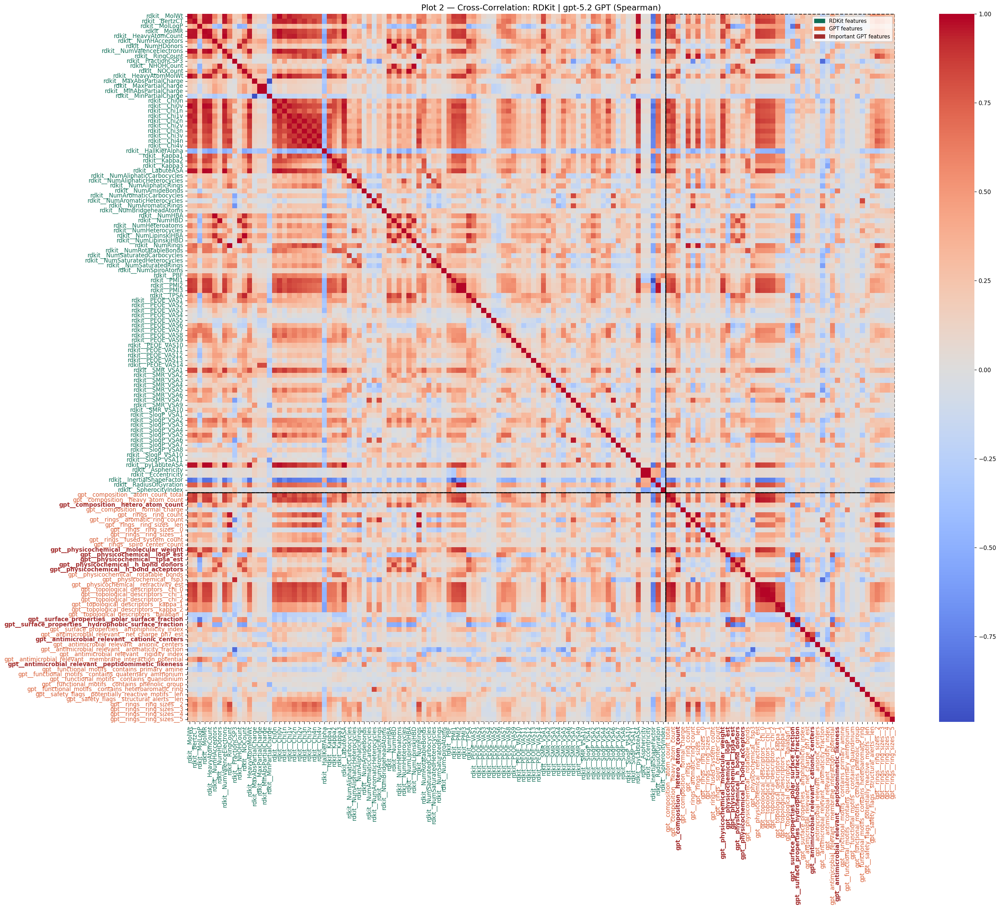

[Plot 3] Ordered Kendall cross-correlation


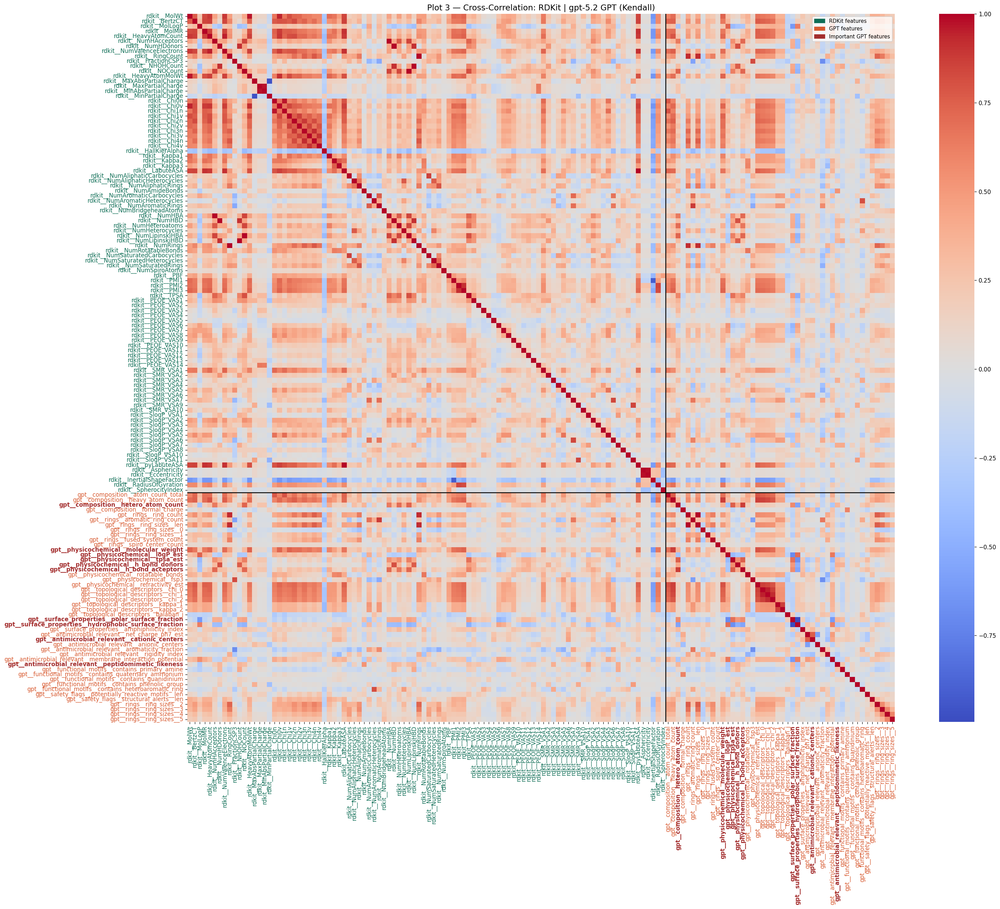

[Plot 4] Clustered heatmap


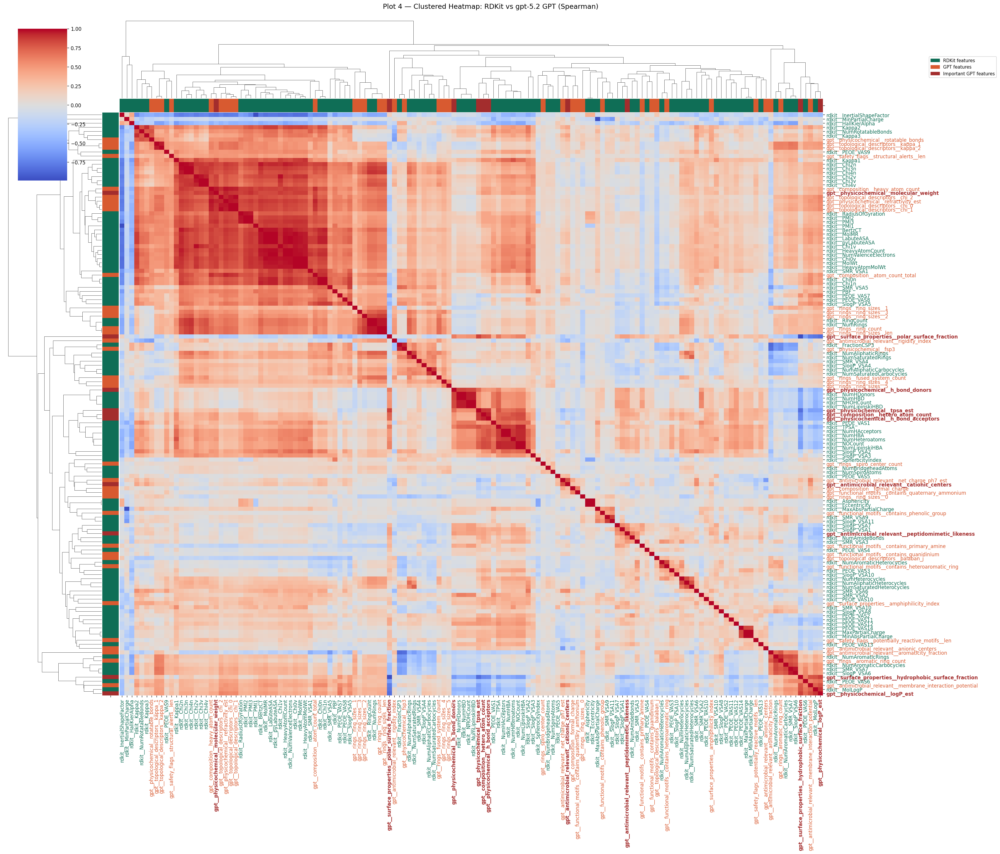

[Plot 5] MolWt scatter
  Spearman r = 0.8660  (p = 0.00e+00)


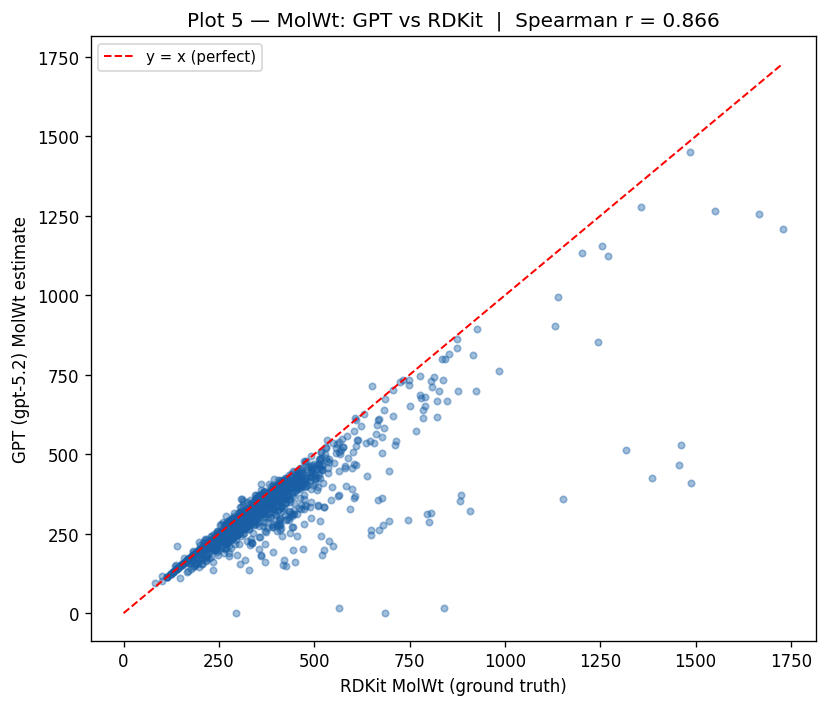

[Plot 6] Correlation network
  Nodes: 142  Edges: 933


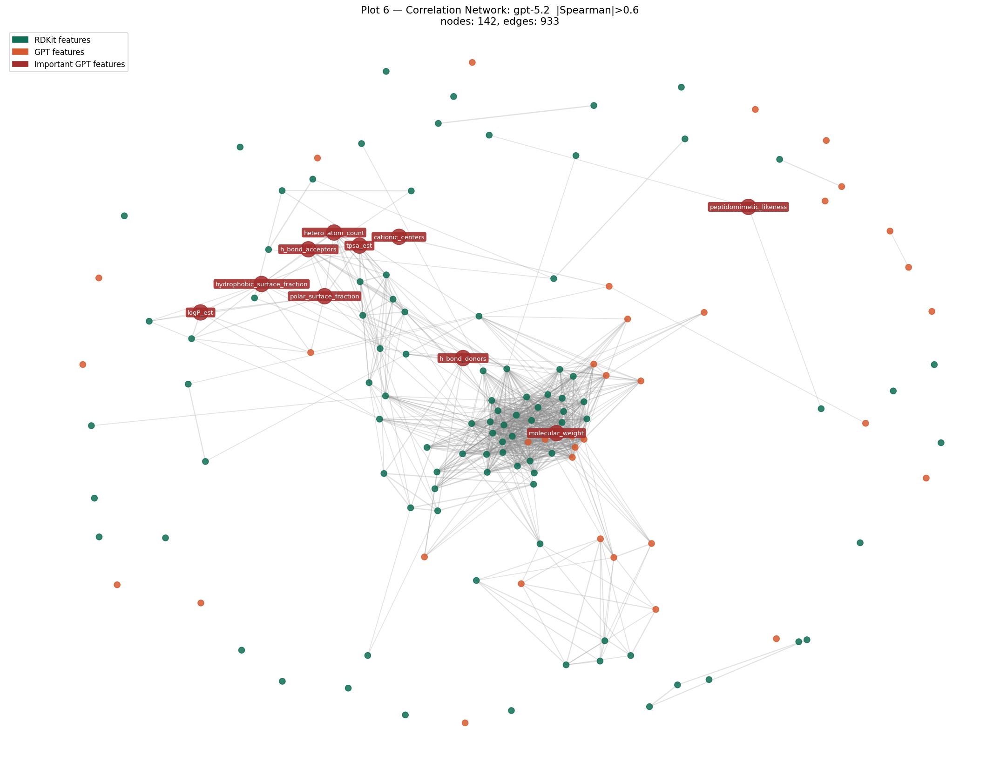

[Plot 7] Novelty bar chart


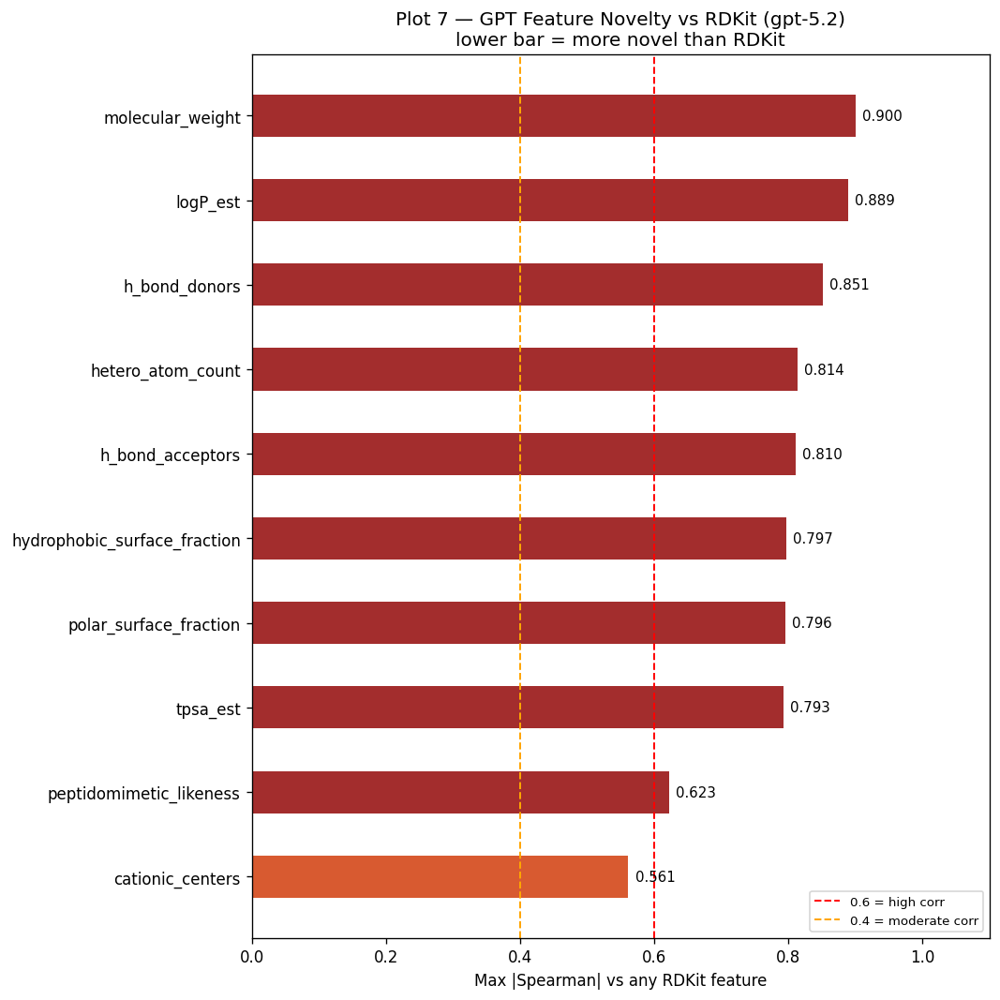


  KEY NOVELTY NUMBERS:
  cationic_centers                          max|r|=0.561  (rdkit__SMR_VSA6)
  peptidomimetic_likeness                   max|r|=0.623  (rdkit__NumAmideBonds)
  tpsa_est                                  max|r|=0.793  (rdkit__TPSA)
  polar_surface_fraction                    max|r|=0.796  (rdkit__MolLogP)
  hydrophobic_surface_fraction              max|r|=0.797  (rdkit__MolLogP)
  h_bond_acceptors                          max|r|=0.810  (rdkit__NOCount)
  hetero_atom_count                         max|r|=0.814  (rdkit__NOCount)
  h_bond_donors                             max|r|=0.851  (rdkit__NumHDonors)
  logP_est                                  max|r|=0.889  (rdkit__MolLogP)
  molecular_weight                          max|r|=0.900  (rdkit__PMI3)

  Plots saved to: D:\Hiwi\GPT+Mole\GPT+Mole\data\plots_final\gpt-5.2

  MODEL: gpt-4.1-mini-v2
Loading data...
  RDKit: (1197, 96)  GPT: (1197, 143)  Important: 10
  Important features: ['hetero_atom_count', 'aliphatic_ri

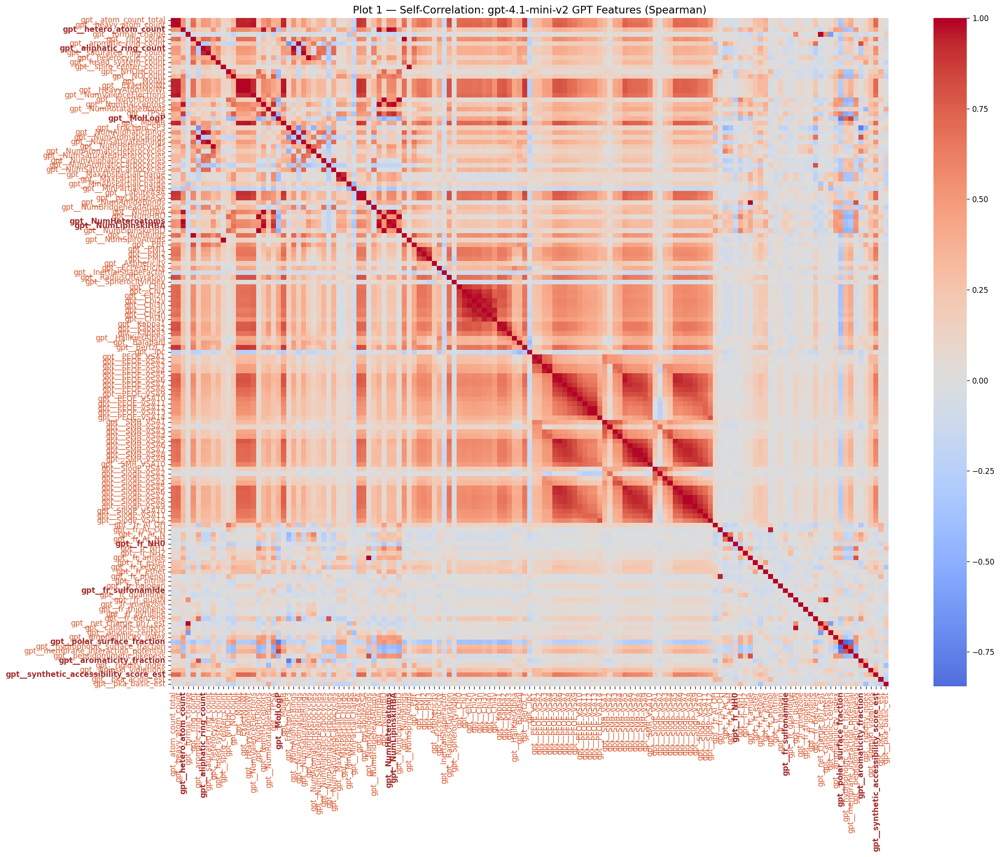

[Plot 2] Ordered Spearman cross-correlation


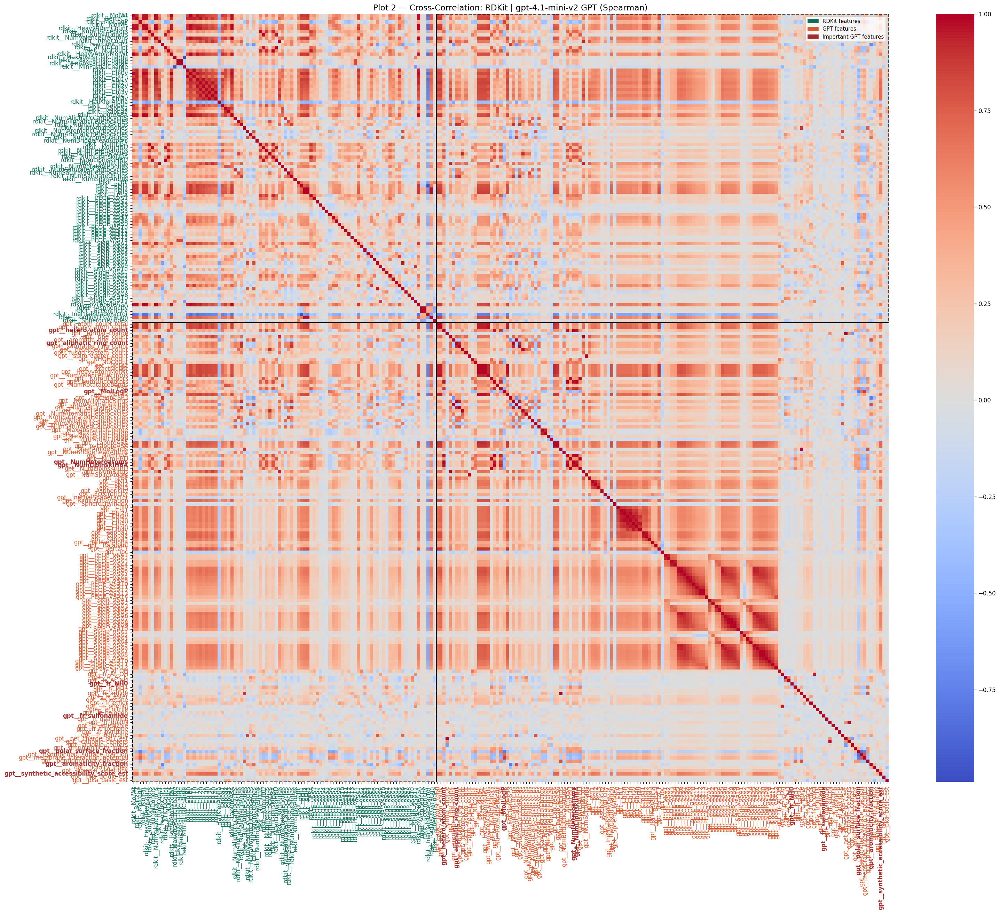

[Plot 3] Ordered Kendall cross-correlation


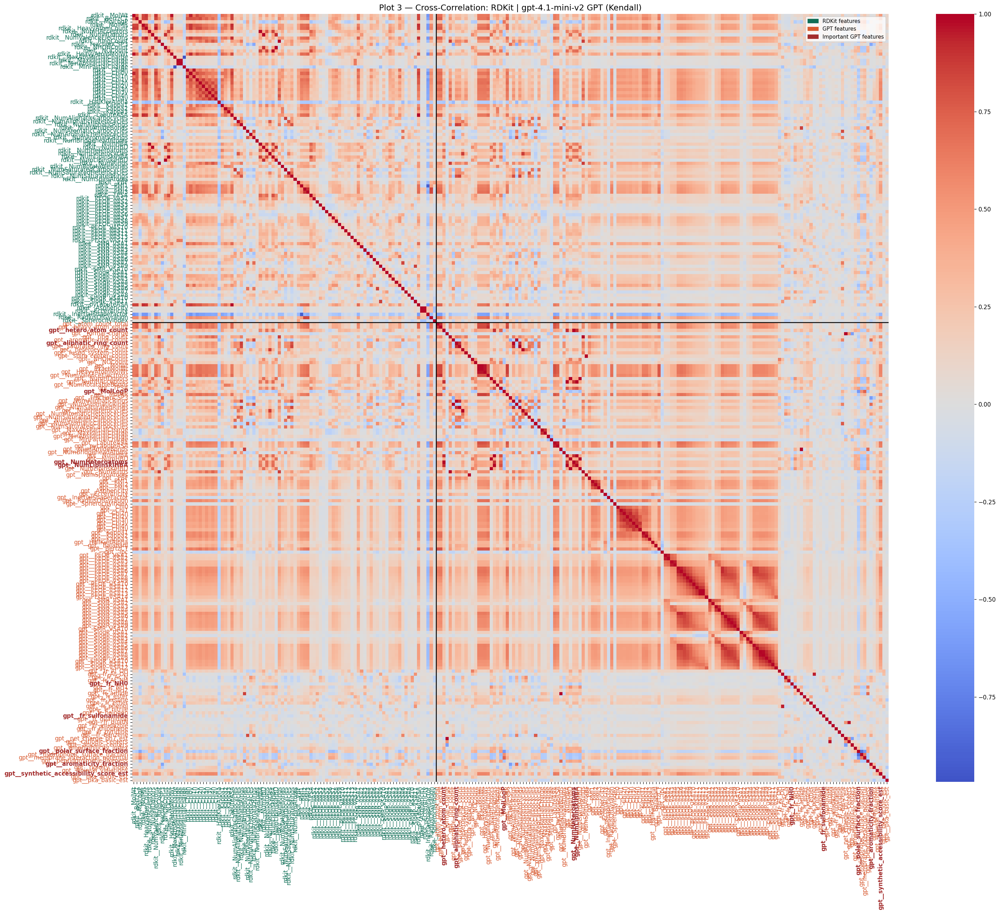

[Plot 4] Clustered heatmap


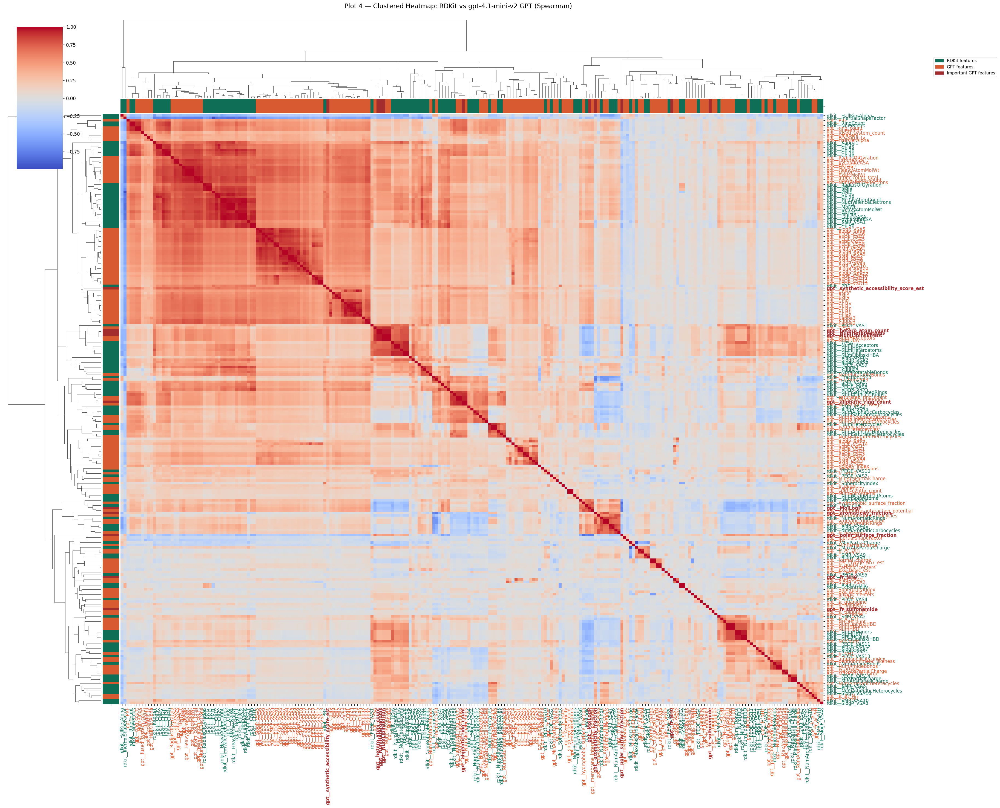

[Plot 5] MolWt scatter
  Spearman r = 0.8123  (p = 3.89e-282)


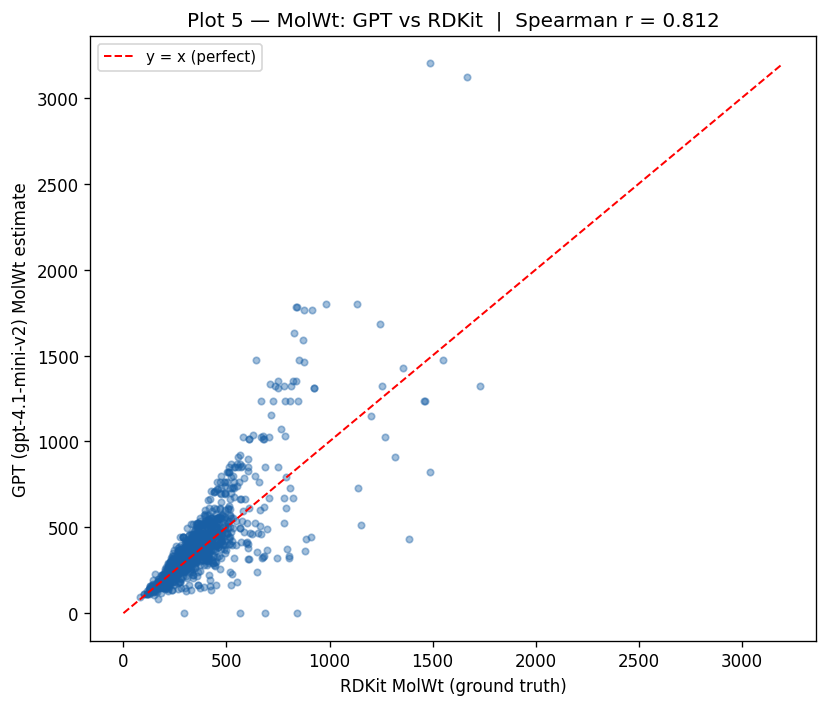

[Plot 6] Correlation network
  Nodes: 239  Edges: 2259


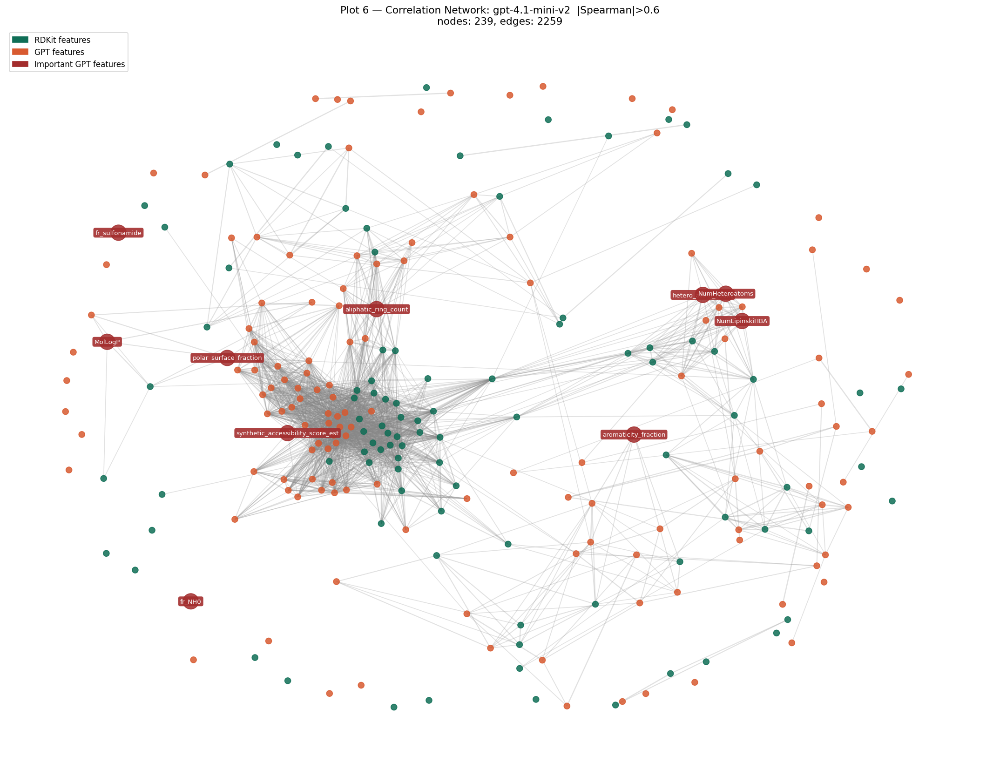

[Plot 7] Novelty bar chart


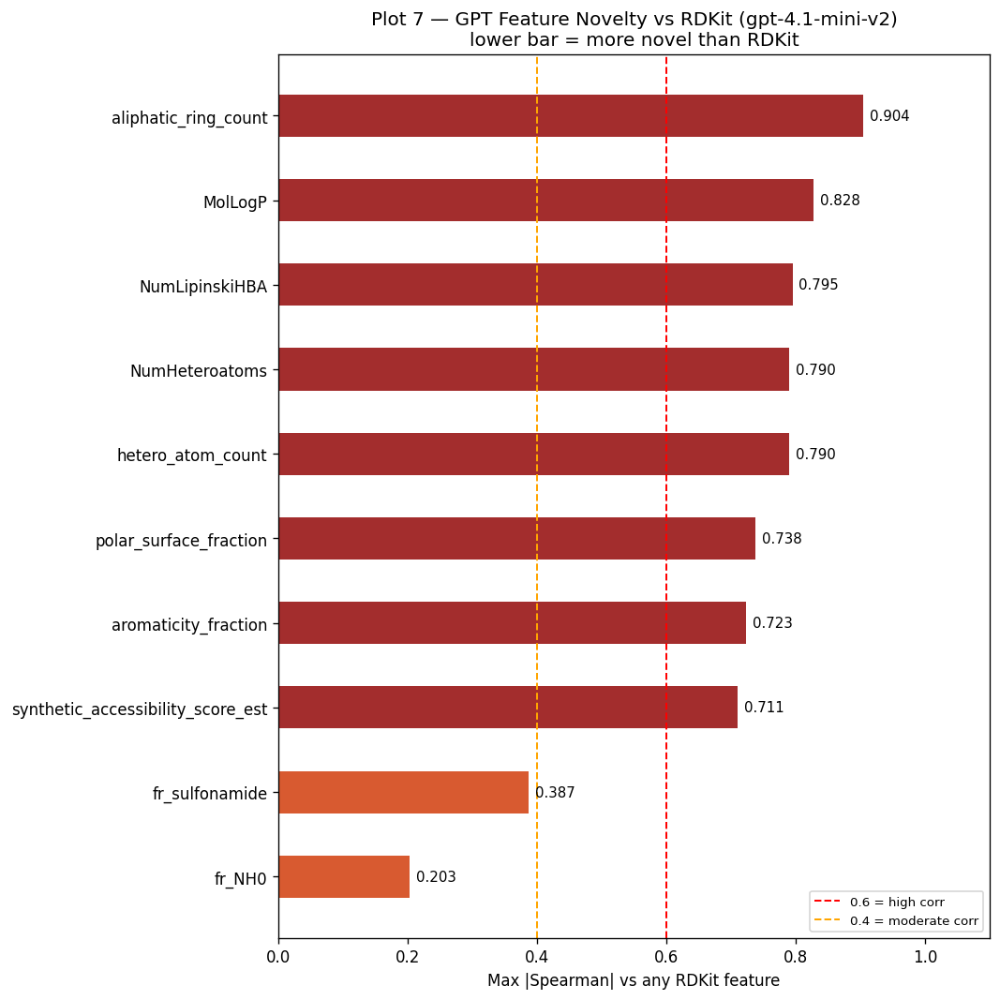


  KEY NOVELTY NUMBERS:
  fr_NH0                                    max|r|=0.203  (rdkit__NHOHCount)
  fr_sulfonamide                            max|r|=0.387  (rdkit__PEOE_VAS3)
  synthetic_accessibility_score_est         max|r|=0.711  (rdkit__Chi3n)
  aromaticity_fraction                      max|r|=0.723  (rdkit__FractionCSP3)
  polar_surface_fraction                    max|r|=0.738  (rdkit__MolLogP)
  hetero_atom_count                         max|r|=0.790  (rdkit__NumHeteroatoms)
  NumHeteroatoms                            max|r|=0.790  (rdkit__NumHeteroatoms)
  NumLipinskiHBA                            max|r|=0.795  (rdkit__NOCount)
  MolLogP                                   max|r|=0.828  (rdkit__MolLogP)
  aliphatic_ring_count                      max|r|=0.904  (rdkit__NumAliphaticRings)

  Plots saved to: D:\Hiwi\GPT+Mole\GPT+Mole\data\plots_final\gpt-4.1-mini-v2


In [16]:
# Run all models one after another
for model_key in MODEL_CONFIGS:
    run_model(model_key)
